# <center> **MATH&ML-9. Математика ансамблевых методов**

Составление прогнозов в машинном обучении может следовать такой же логике: один алгоритм часто даёт далёкий от желаемой точности прогноз, ведь у каждого метода есть свои ограничения, и в целом создание модели, которая строит очень близкие к реальности предсказания, — достаточно сложная задача. Однако если мы обучим на наших данных несколько моделей и обобщим результаты определённым образом, то сможем получить куда более точный результат.

Такой алгоритм решения задач машинного обучения называется **ансамблем моделей**.

>**Ансамбль моделей** — это метод, в котором несколько алгоритмов (или вариации одного и того же) обучаются на одних данных, а итоговый прогноз строится на основе всех полученных от моделей прогнозов.

## <center> 2. Ансамбли моделей. Бутстреппинг. Бэггинг

В основе бэггинга лежит статистический метод, который называется бутстрепом (bootstrap). Идея бутстрепа заключается в генерации выборок размера n из исходного датасета размера N путём случайного выбора элементов с повторениями в каждом из наблюдений.

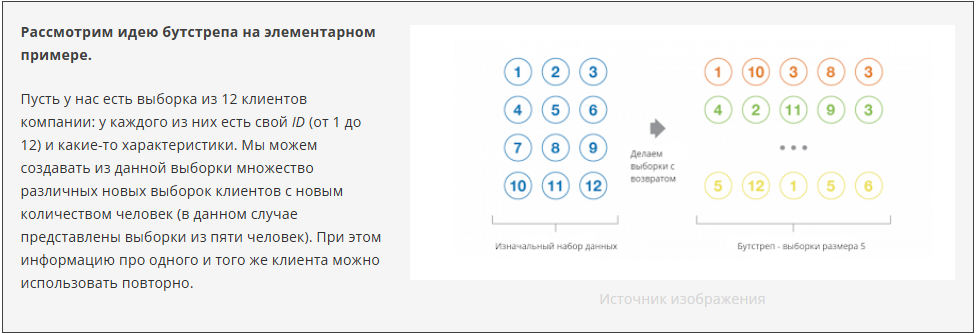

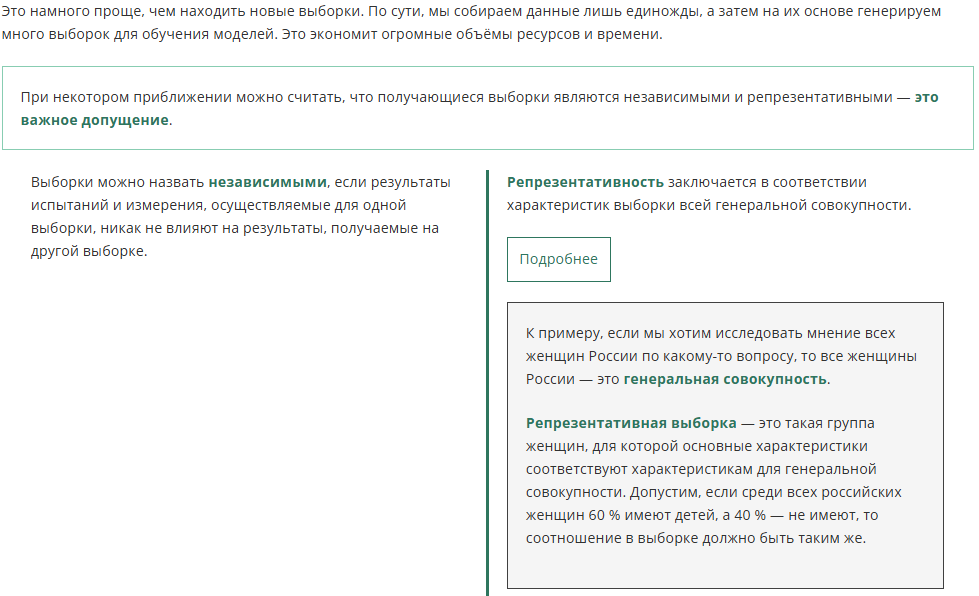

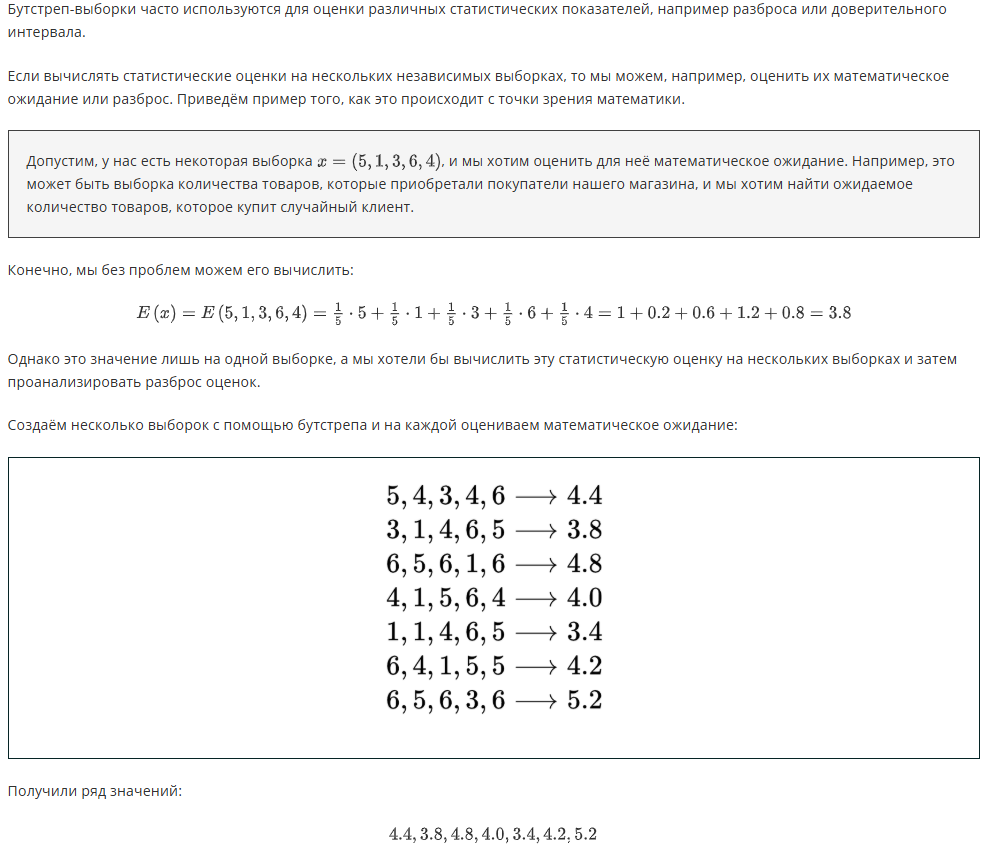

D(x)=0.317

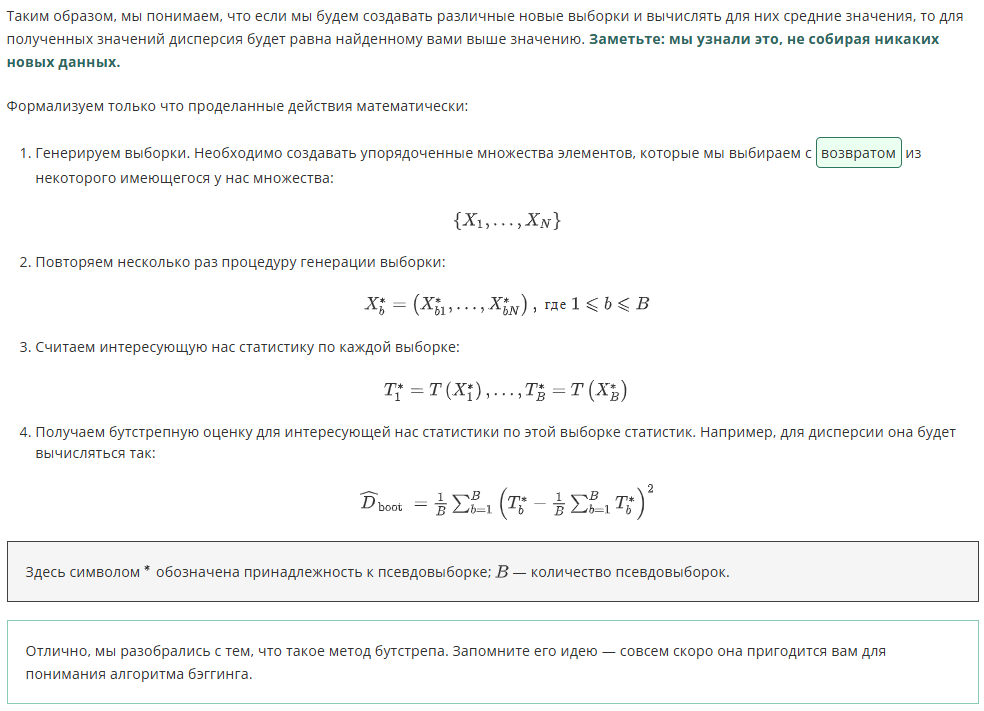

## <center> Bias и Variance

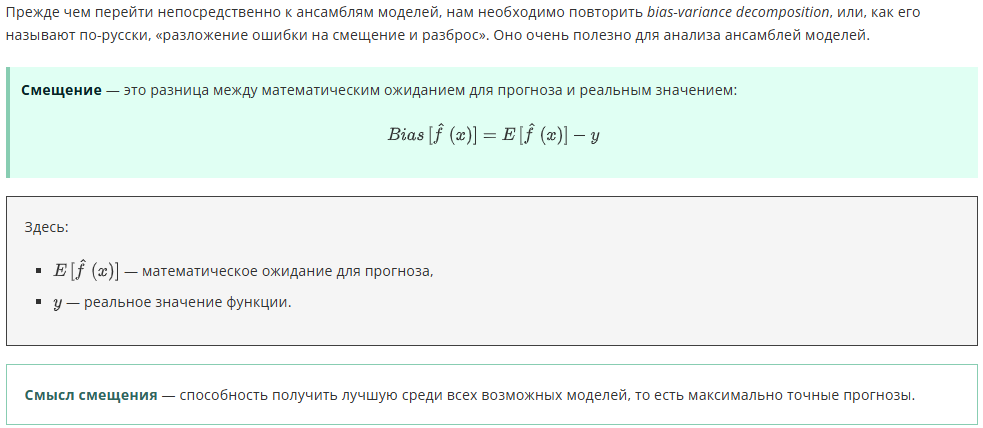

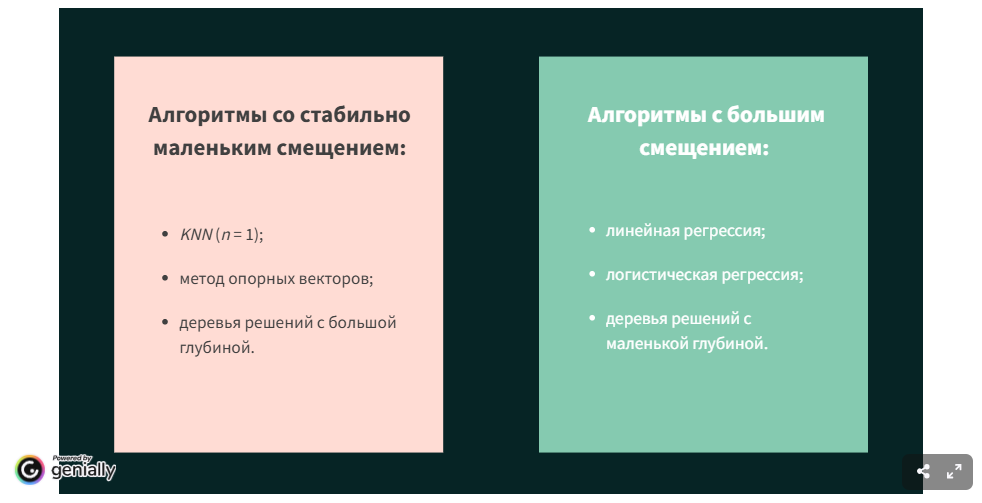

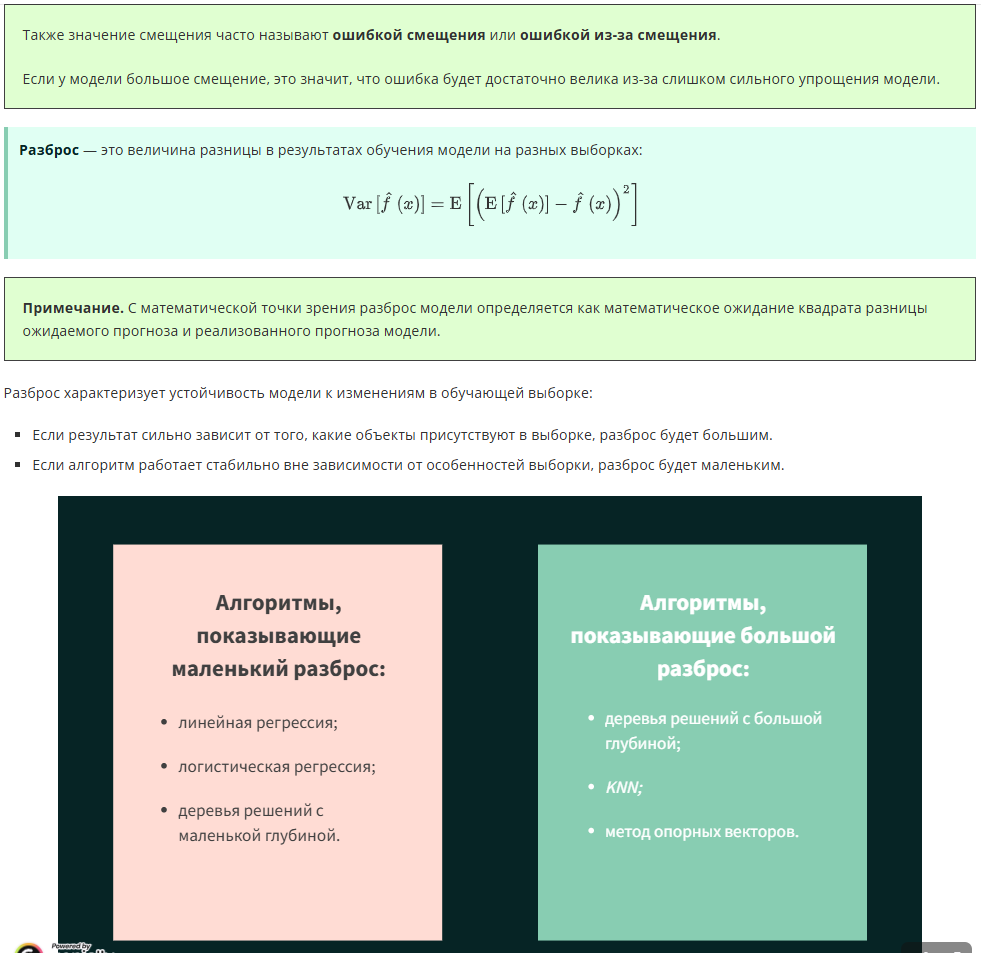

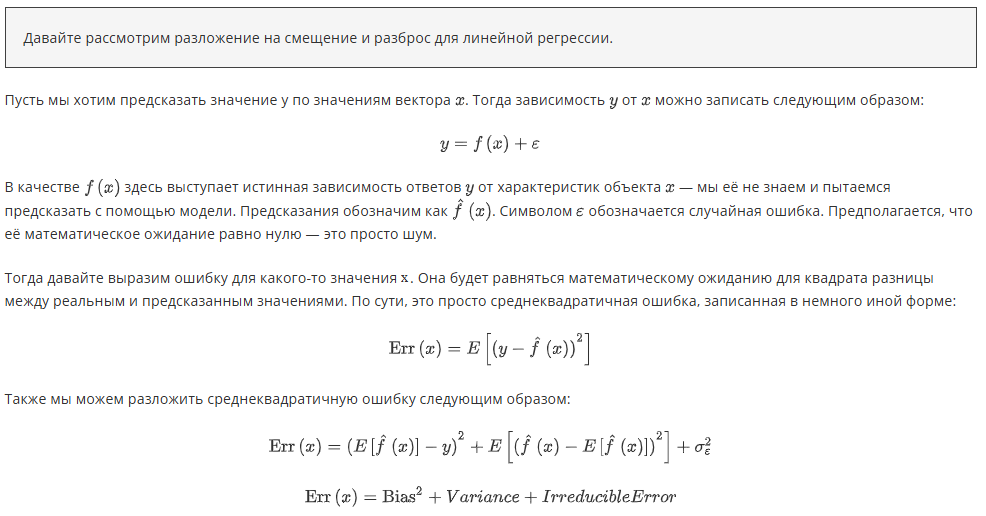

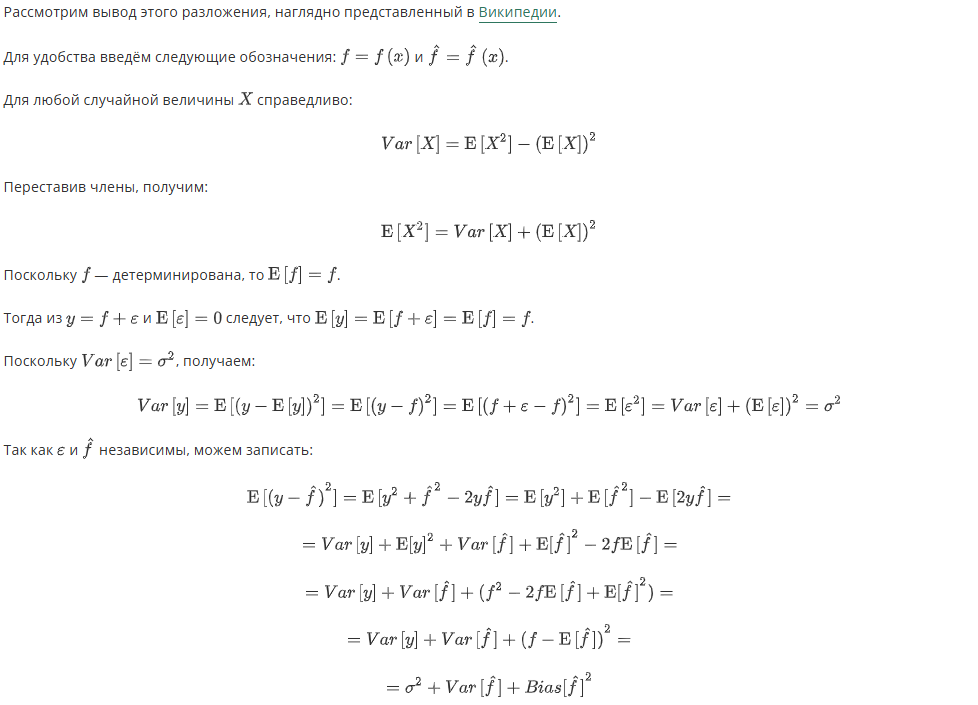

Итак, мы получили, что наша ошибка — это сумма квадрата смещения, разброса и неустранимой случайной ошибки. Теперь мы понимаем, из чего состоит ошибка модели. Такое представление помогает нам исследовать с теоретической точки зрения некоторые алгоритмы машинного обучения и часто используется при изучении ансамблей.

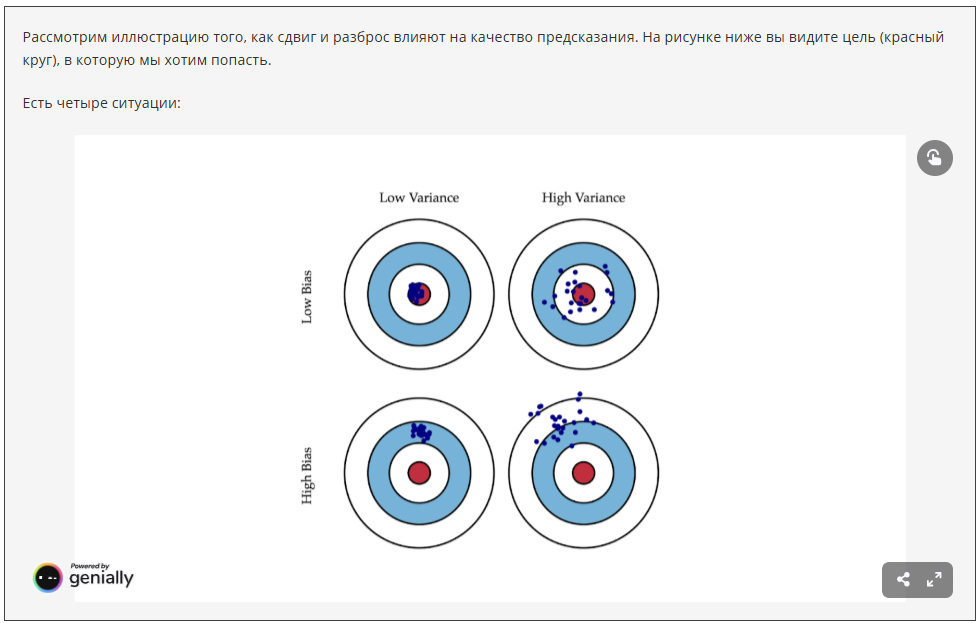

В моделях машинного обучения принцип тот же, только в качестве центра мишени выступает минимально возможная ошибка.

Когда говорят про разложение на *bias* и *variance*, то часто упоминают некую **точку баланса**:
* Если модель очень простая, с маленьким количеством параметров, то, скорее всего, у неё будет **очень большое смещение, но маленький разброс**.
* Если модель очень сложная, со множеством параметров, у неё будет **большой разброс и маленькое смещение**.

Схематично эти зависимости можно изобразить следующим образом (это схема не для конкретной модели, а лишь иллюстрация тенденций):

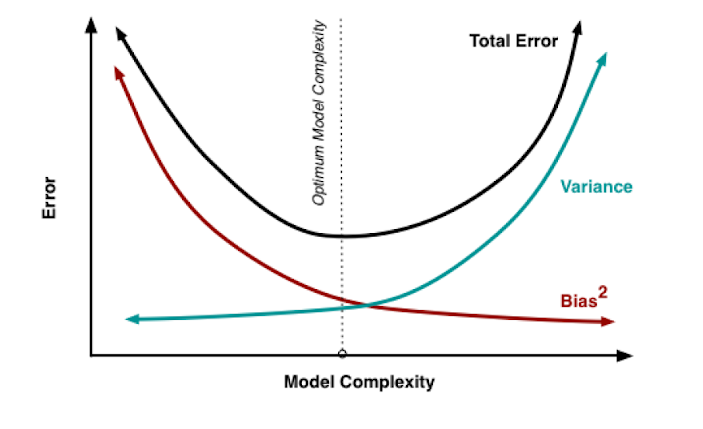

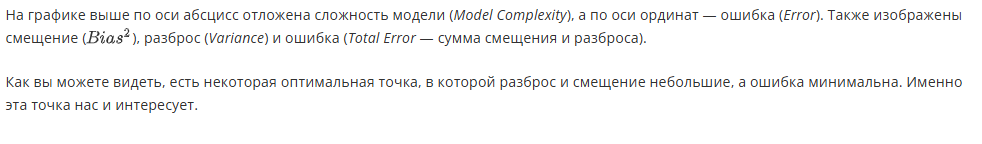

## <center> Бэггинг

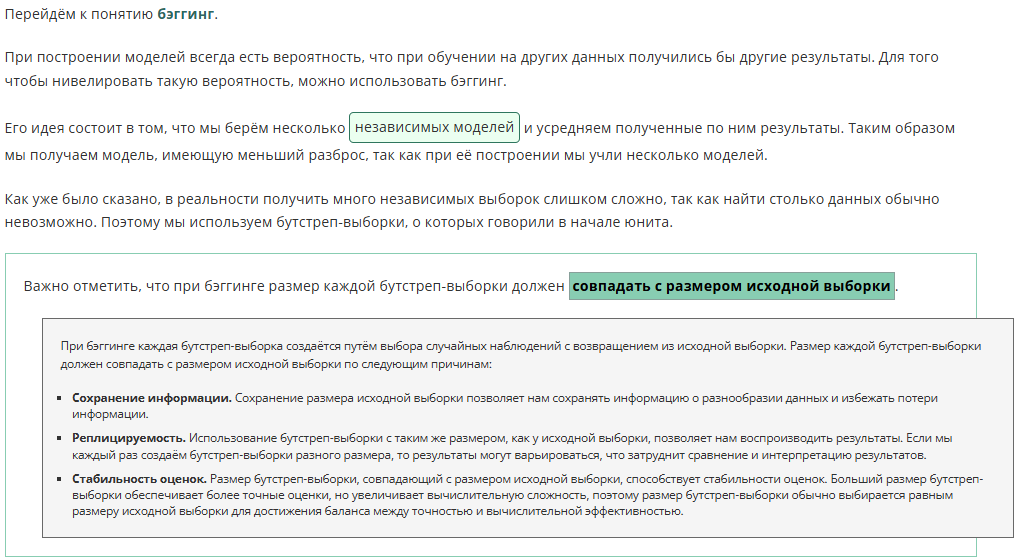

Схематично процесс бэггинга можно представить следующим образом:

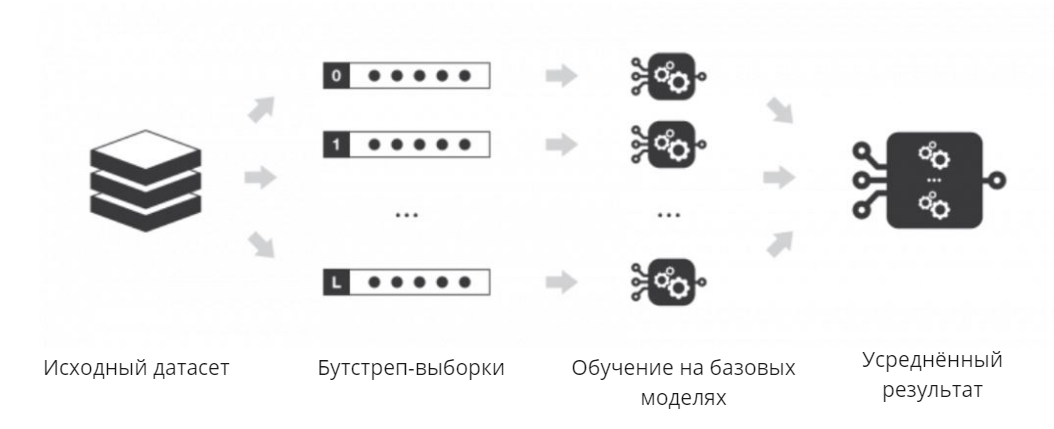

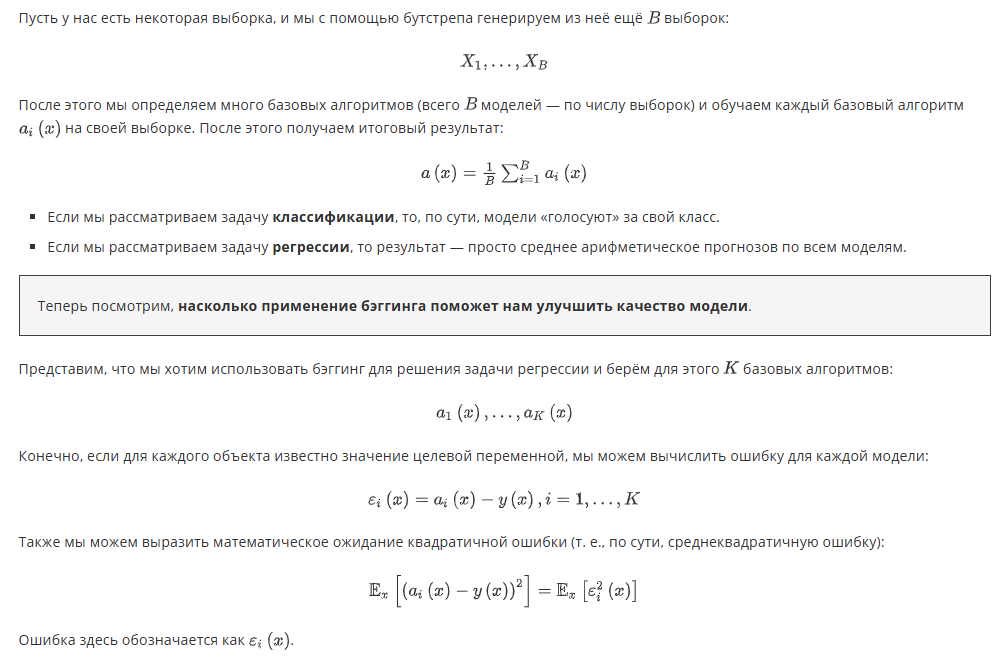

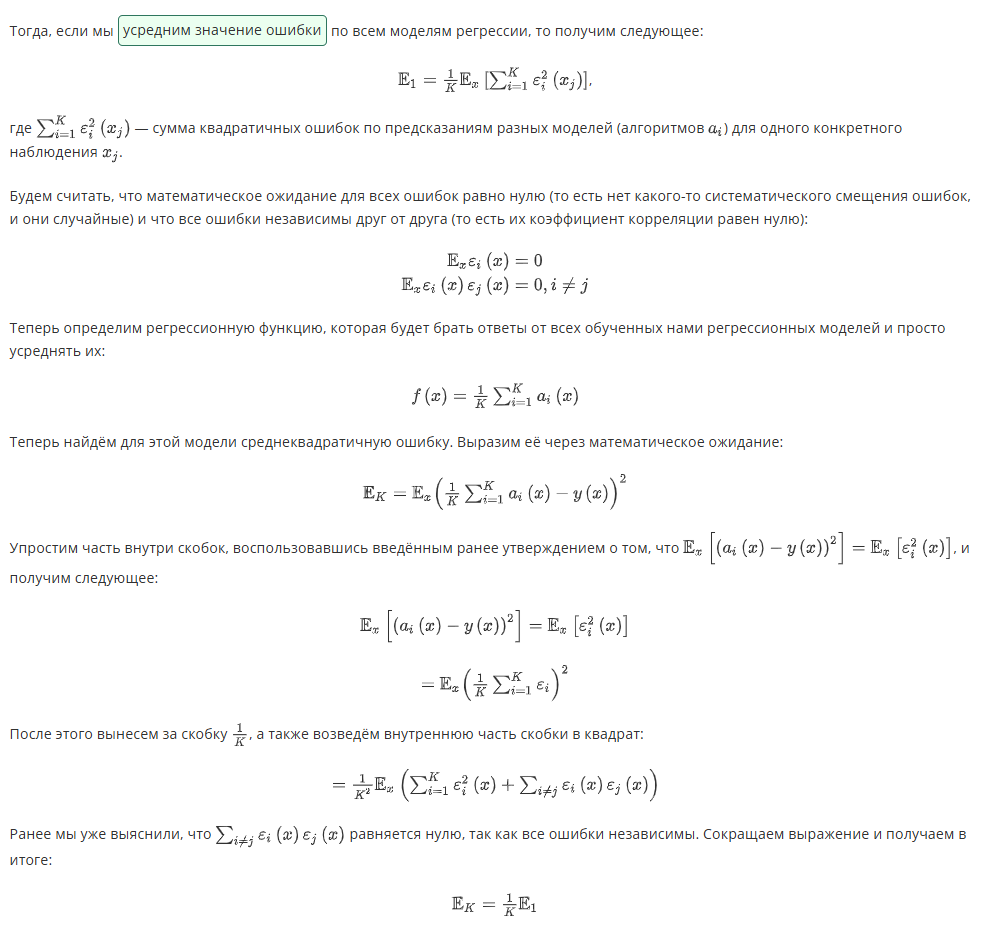

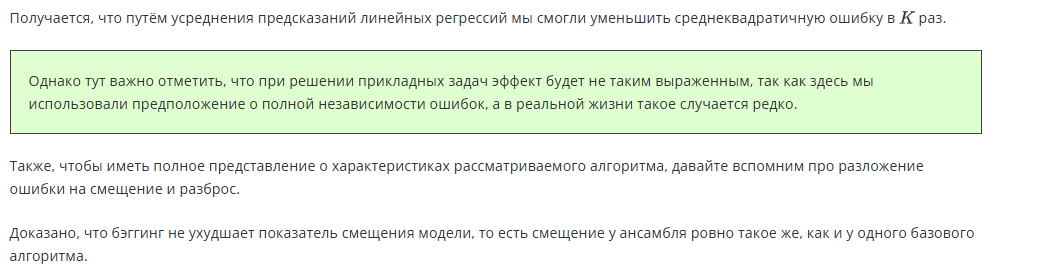

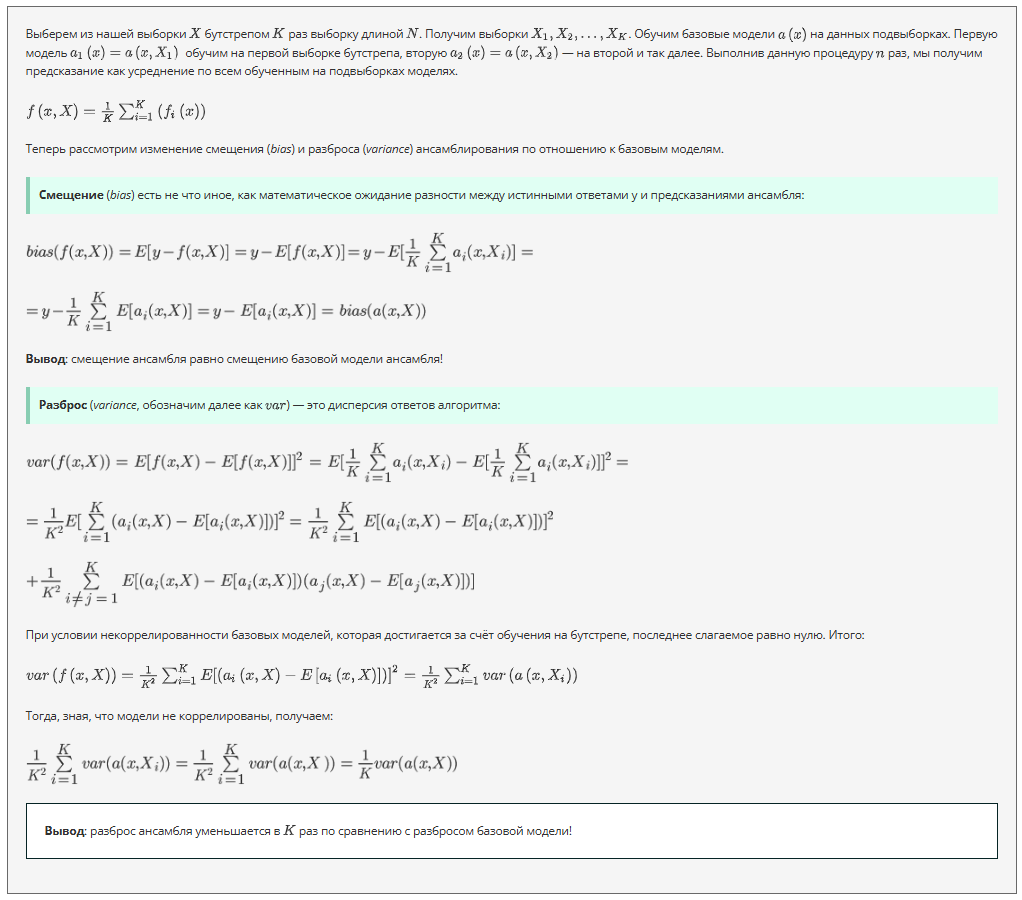

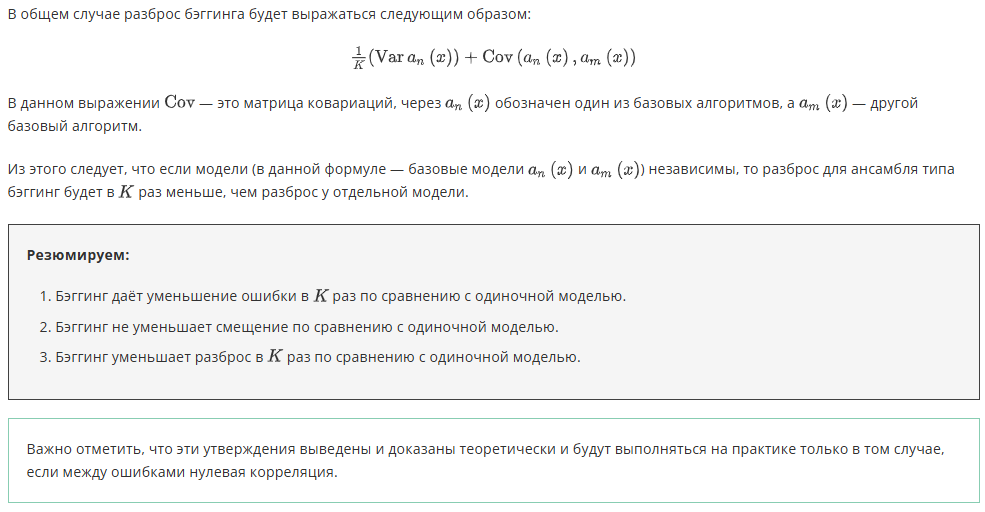

In [1]:
import pandas as pd
df = pd.read_csv('data/wineQualityReds.csv')
df = df.drop('Unnamed: 0',axis=1)
df

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [2]:
df['target']=df['quality'].apply(lambda x: 1 if x >=6 else 0)
df.sample(10)

,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality,target
94,5.0,1.020,0.04,1.4,0.045,41.0,85.0,0.99380,3.75,0.48,10.5,4,0
1246,7.4,0.740,0.07,1.7,0.086,15.0,48.0,0.99502,3.12,0.48,10.0,5,0
598,8.5,0.585,0.18,2.1,0.078,5.0,30.0,0.99670,3.20,0.48,9.8,6,1
403,11.4,0.600,0.49,2.7,0.085,10.0,41.0,0.99940,3.15,0.63,10.5,6,1
1048,9.3,0.490,0.36,1.7,0.081,3.0,14.0,0.99702,3.27,0.78,10.9,6,1
256,9.4,0.340,0.37,2.2,0.075,5.0,13.0,0.99800,3.22,0.62,9.2,5,0
195,7.8,0.590,0.33,2.0,0.074,24.0,120.0,0.99680,3.25,0.54,9.4,5,0
1146,7.8,0.500,0.12,1.8,0.178,6.0,21.0,0.99600,3.28,0.87,9.8,6,1
1561,7.8,0.600,0.26,2.0,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,5,0
949,8.9,0.120,0.45,1.8,0.075,10.0,21.0,0.99552,3.41,0.76,11.9,7,1


In [3]:
from sklearn.model_selection import train_test_split
X = df.drop(['target','quality'],axis = 1)
y = df['target']

In [4]:
y.value_counts(normalize=True)

target
1    0.534709
0    0.465291
Name: proportion, dtype: float64

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3,random_state=42,shuffle=True)

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
lg = LogisticRegression(random_state=42)
lg.fit(X_train,y_train)
y_pred = lg.predict(X_test)
print(f1_score(y_test, y_pred))

0.7542857142857143


c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [7]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=10,random_state=42)
dt.fit(X_train,y_train)
y_pred = dt.predict(X_test)
print(f1_score(y_test,y_pred))


0.7927927927927927


In [8]:
from sklearn.ensemble import BaggingClassifier
bc = BaggingClassifier(estimator=dt, n_estimators=1500)
bc.fit(X_train,y_train)
y_pred = bc.predict(X_test)
print(round(f1_score(y_test,y_pred),3))

0.82


---

# <center> **3. Случайный лес**

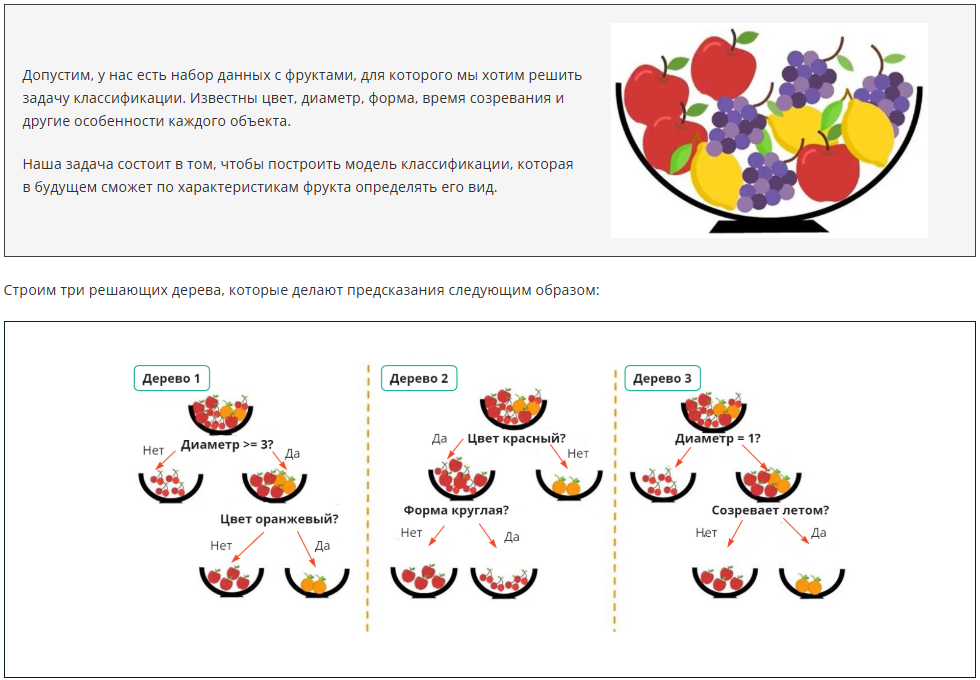

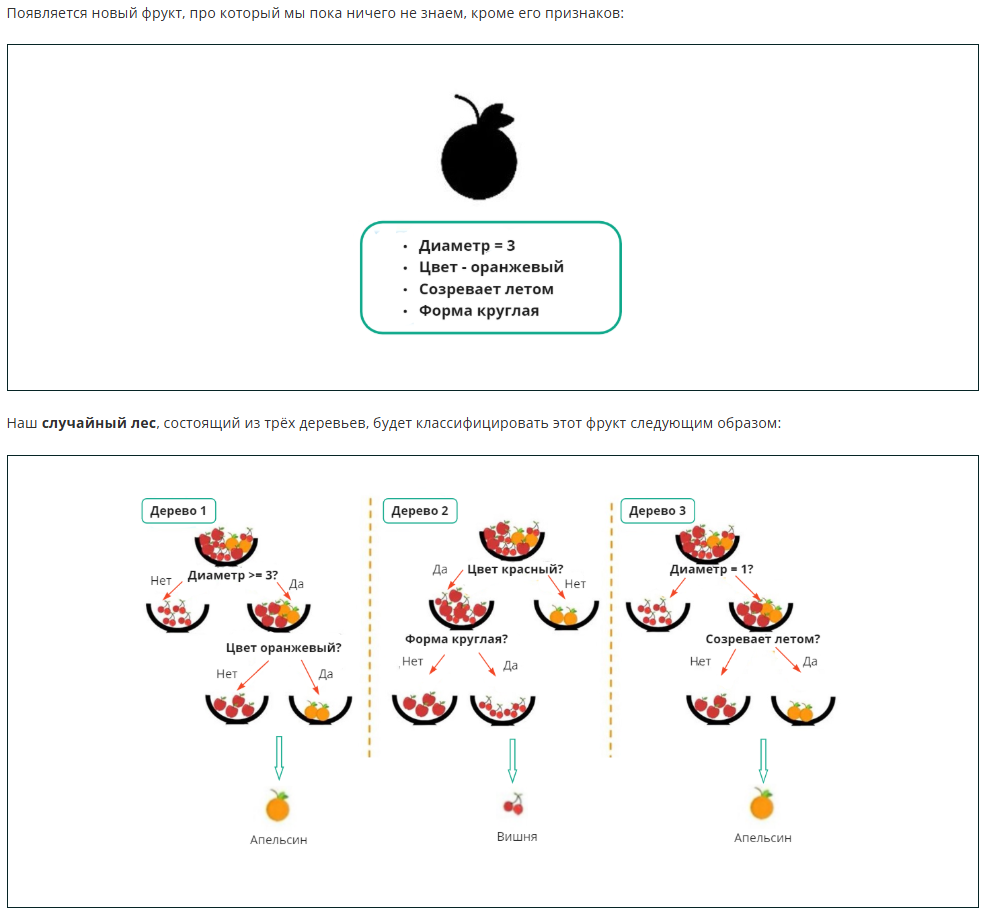

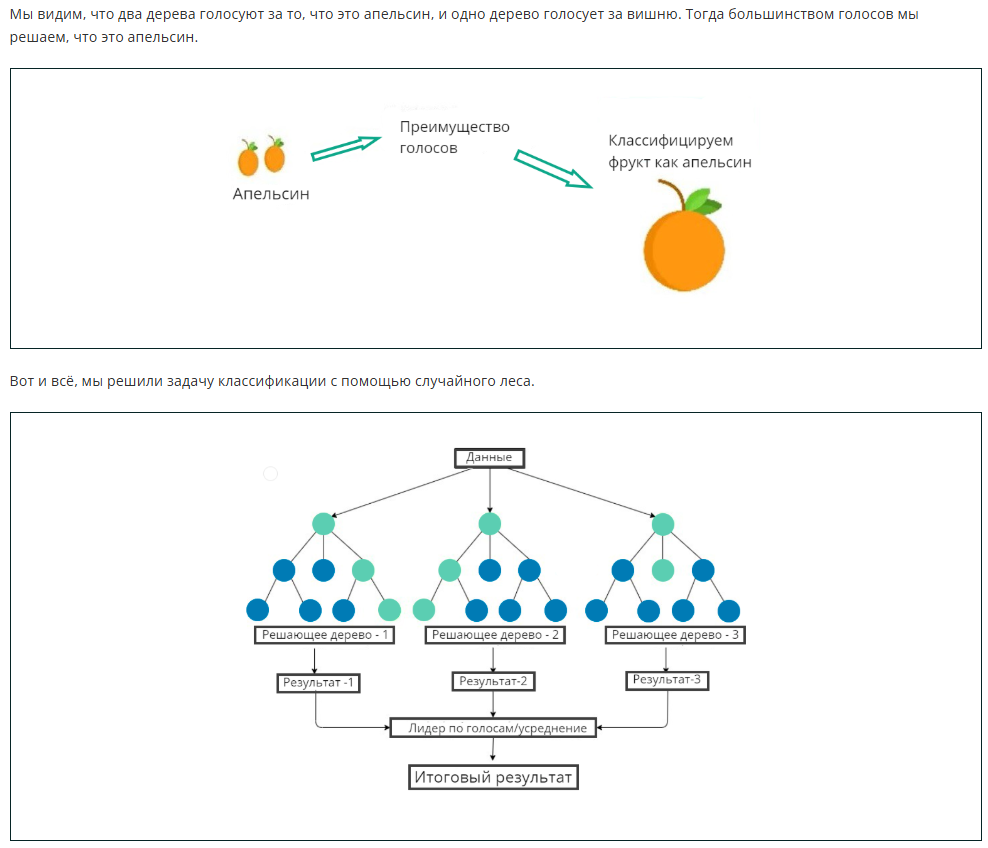

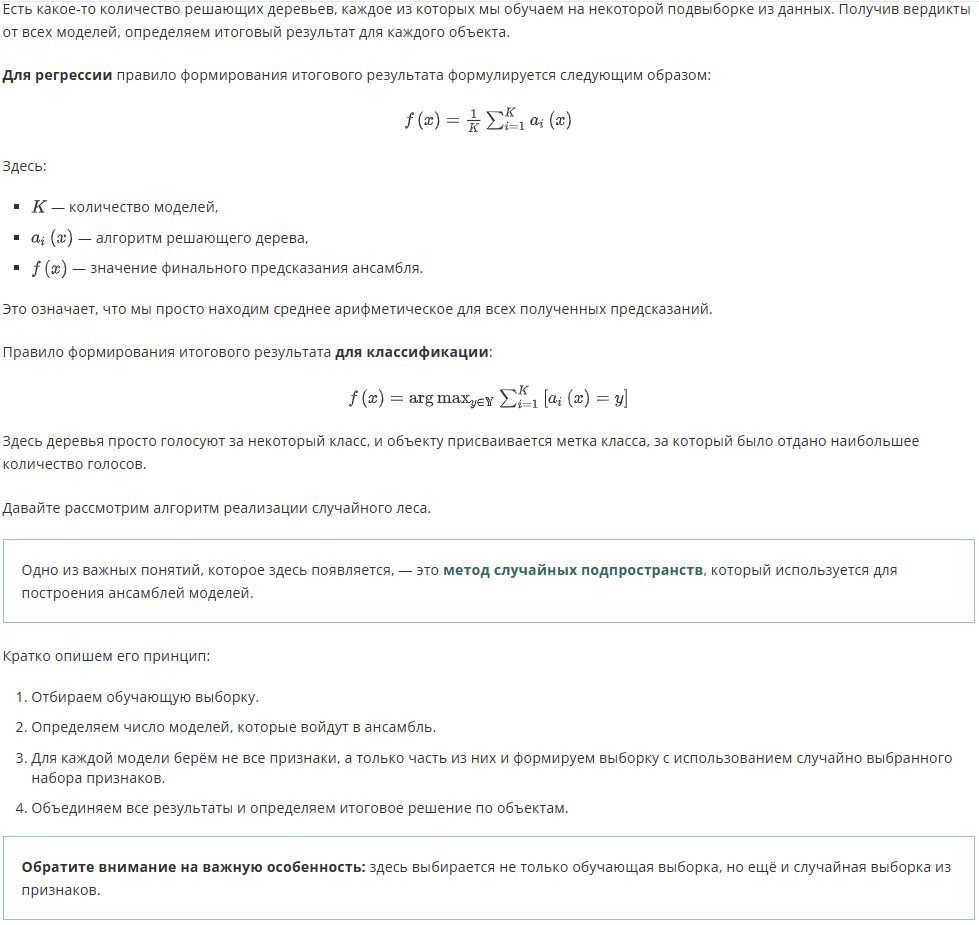

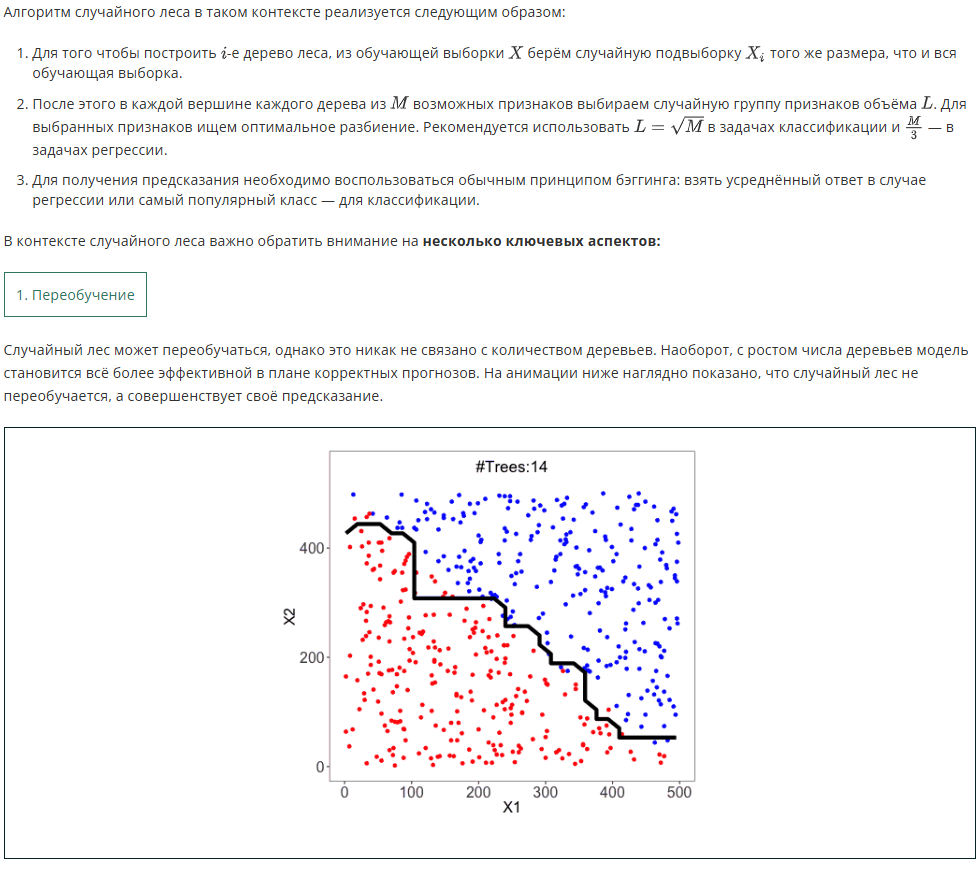

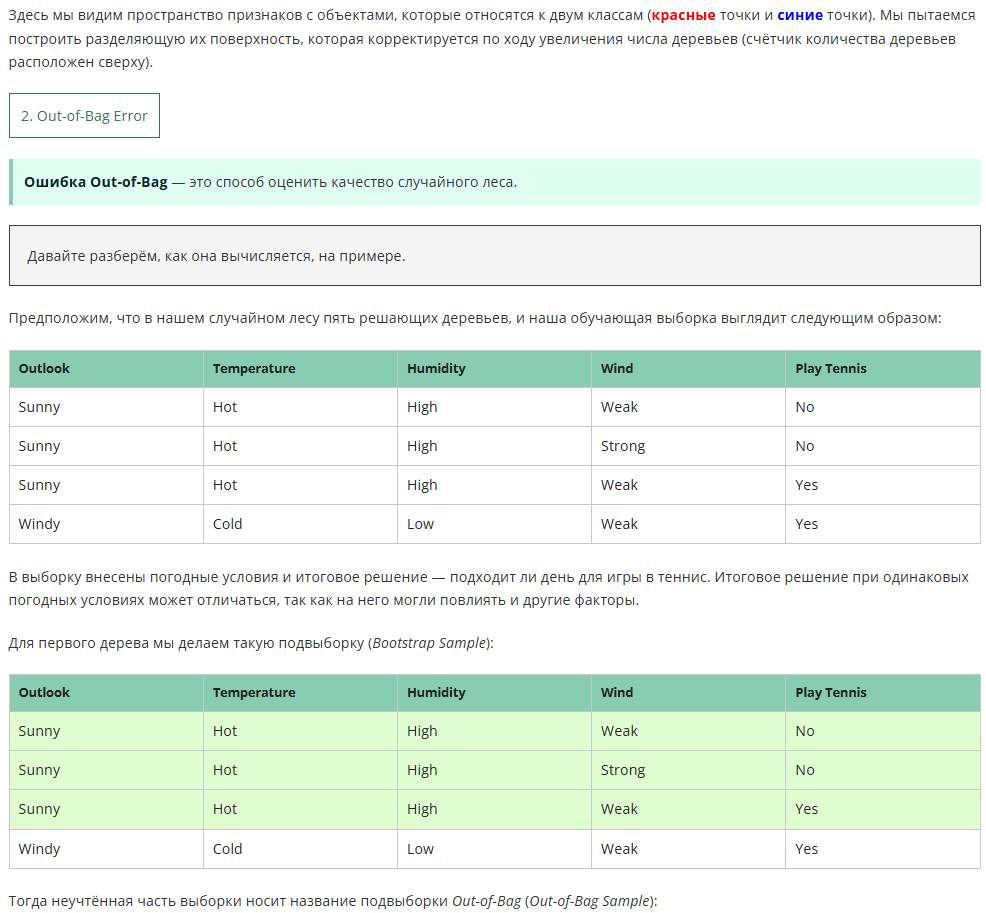

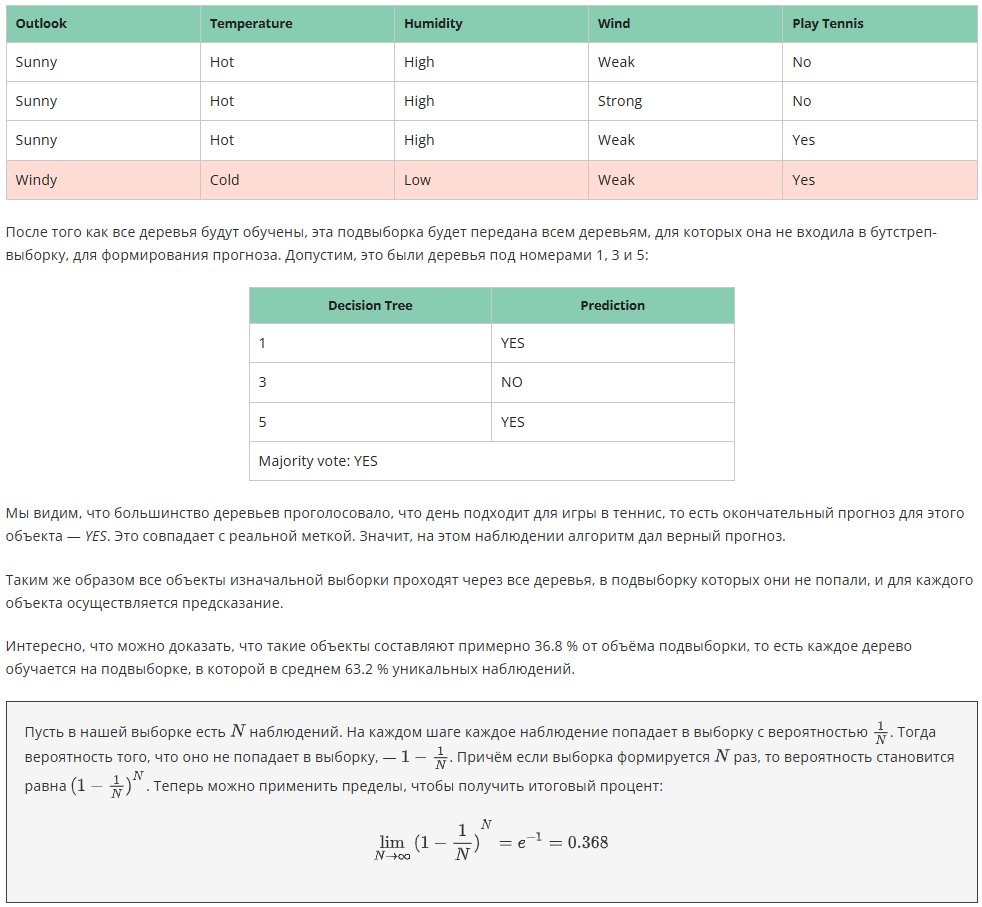

Примечание. Данный переход напрямую следует из второго замечательного предела. К сожалению, эта часть математического анализа выходит за пределы нашего курса, однако если вам интересно изучить её подробнее, рекомендуем ознакомиться с [этим материалом](https://mathprofi.ru/zamechatelnye_predely.html).

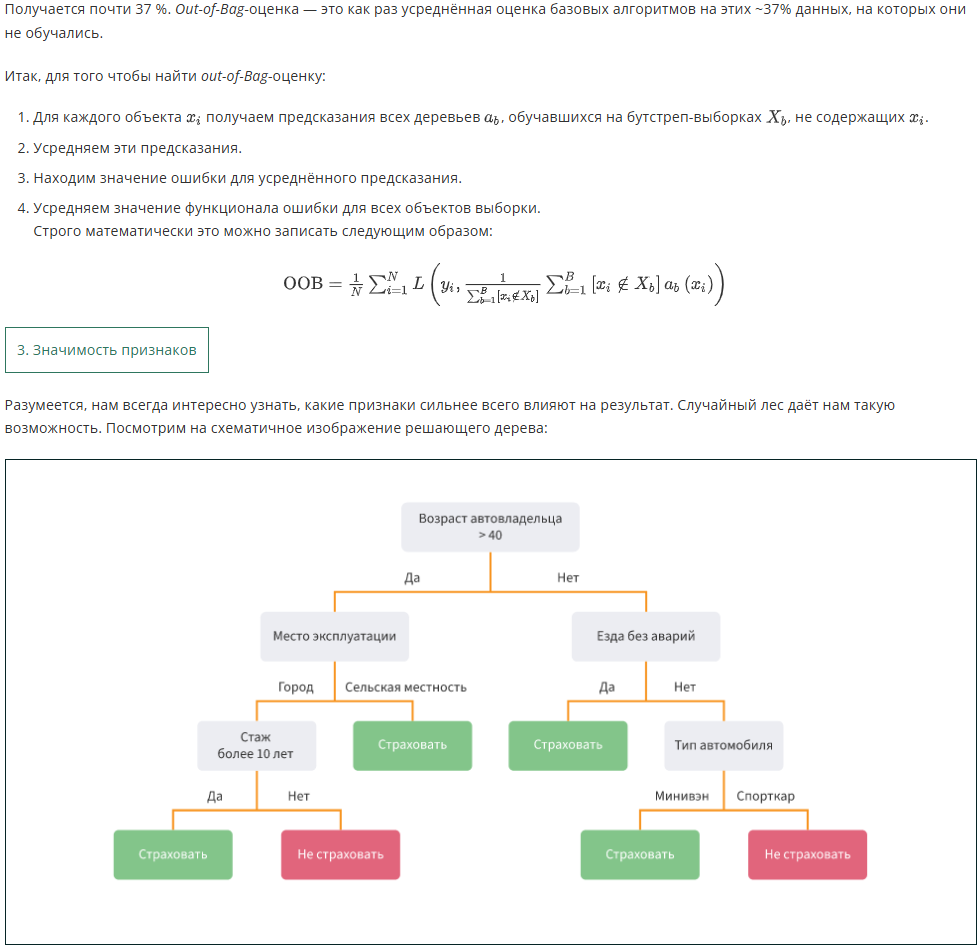

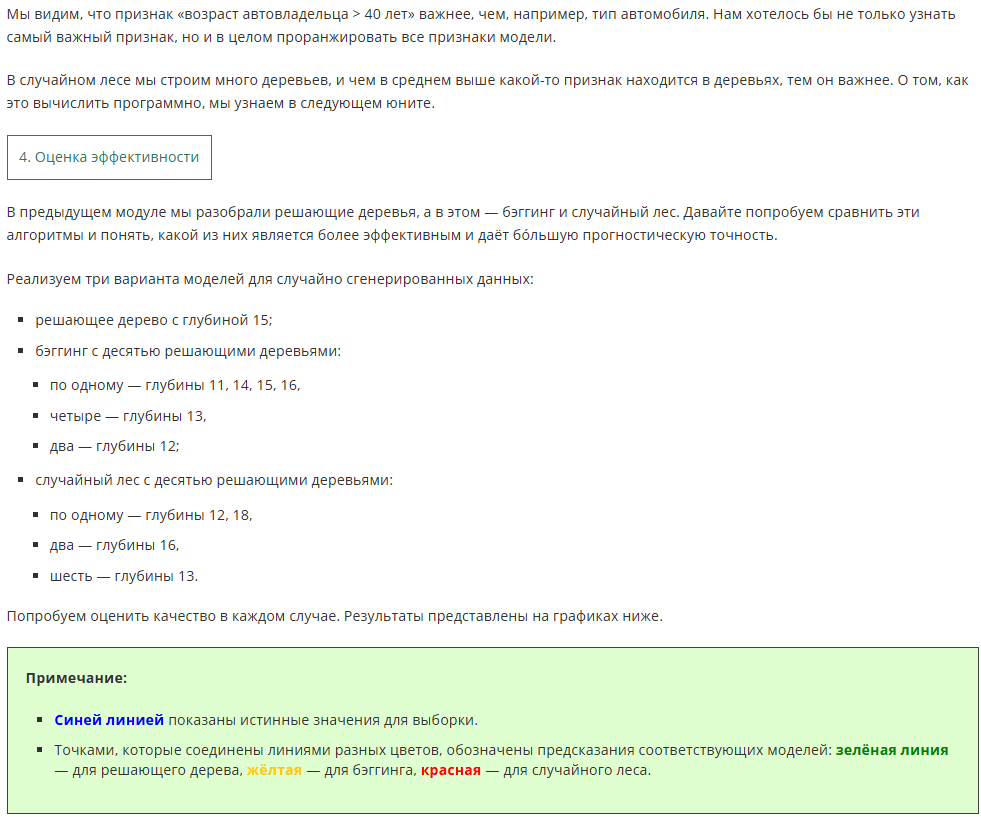

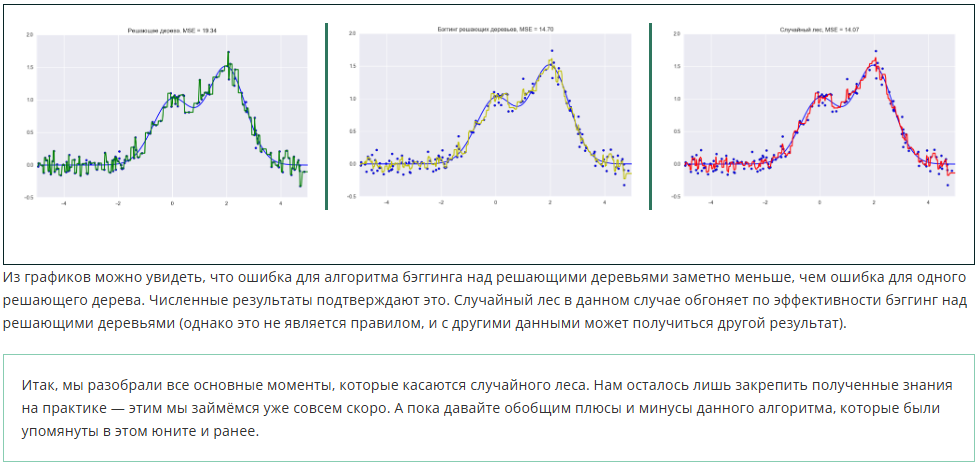

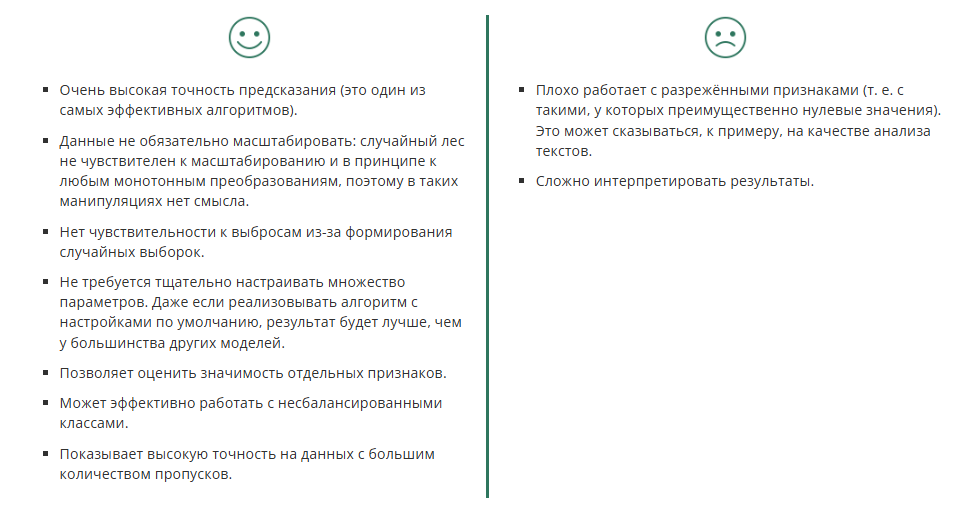

In [9]:
df = pd.read_csv('data/boston (1).csv',decimal=',')
df

,crim_rate,zn,business,river,nit_oxiden,rooms,age,dist,highways_index,tax,pup_per_teaс,lower,target
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0


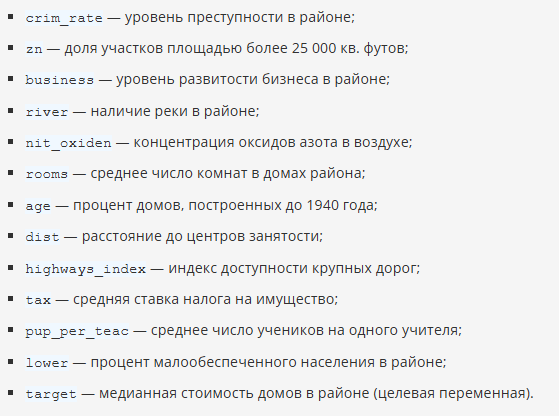

In [10]:
X = df.drop('target',axis = 1)
y = df['target']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=13)

In [12]:
y_train.mean()

22.77316384180791

In [13]:
from sklearn.linear_model import LinearRegression
lr =LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

from sklearn.metrics import mean_absolute_error
print(mean_absolute_error(y_test,y_pred))

3.7222793958561513


In [14]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=13)
dt.fit(X_train,y_train)
y_pred = dt.predict(X_test)
print(mean_absolute_error(y_test,y_pred))

2.8388157894736845


In [15]:
from sklearn.ensemble import RandomForestRegressor
rf1 = RandomForestRegressor(n_estimators=3,random_state=13)
rf2 = RandomForestRegressor(n_estimators=10,random_state=13)
rf3 = RandomForestRegressor(n_estimators=100,random_state=13)
rf4 = RandomForestRegressor(n_estimators=500,random_state=13)
rf1.fit(X_train,y_train)
rf2.fit(X_train,y_train)
rf3.fit(X_train,y_train)
rf4.fit(X_train,y_train)
y_pred1 = rf1.predict(X_test)
y_pred2 = rf2.predict(X_test)
y_pred3 = rf3.predict(X_test)
y_pred4 = rf4.predict(X_test)
print(f"1 лес {mean_absolute_error(y_test,y_pred1)}")
print(f"2 лес {mean_absolute_error(y_test,y_pred2)}")
print(f"3 лес {mean_absolute_error(y_test,y_pred3)}")
print(f"4 лес {mean_absolute_error(y_test,y_pred4)}")

1 лес 2.9328947368421057
2 лес 2.466315789473684
3 лес 2.2559736842105265
4 лес 2.2365657894736892


---

## <center> 4. Случайный лес. Практика

In [34]:
import pandas as pd
df = pd.read_csv('data/weatherAUS.csv')
df.head(3)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No


In [17]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

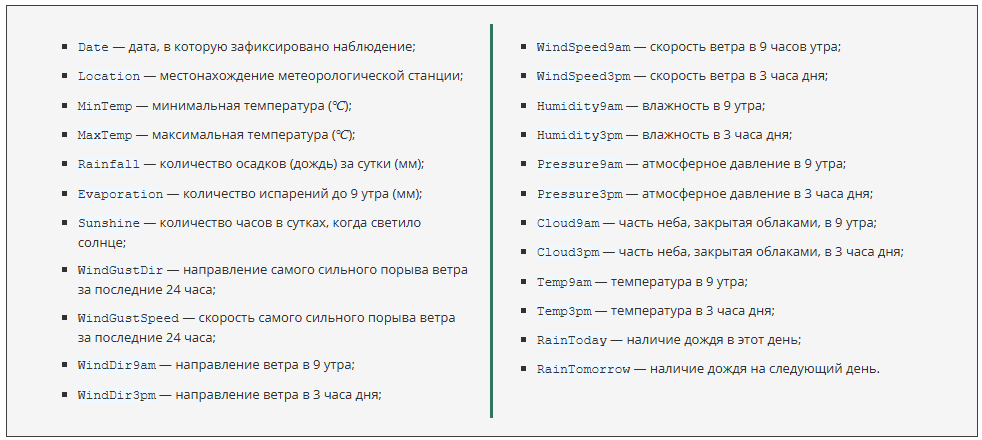

In [35]:
df.isna().sum().sum()

343248

In [36]:
# Проверка на пропуски
cols_null_percent = df.isnull().mean() * 100
cols_with_null = cols_null_percent[cols_null_percent>0].sort_values(ascending=False)
if cols_with_null.empty:
    print("Пропусков в датасете нет.")
else:
    print("Столбцы с пропусками (в процентах):")
    print(cols_with_null)

Столбцы с пропусками (в процентах):
Sunshine         48.009762
Evaporation      43.166506
Cloud3pm         40.807095
Cloud9am         38.421559
Pressure9am      10.356799
Pressure3pm      10.331363
WindDir9am        7.263853
WindGustDir       7.098859
WindGustSpeed     7.055548
Humidity3pm       3.098446
WindDir3pm        2.906641
Temp3pm           2.481094
RainTomorrow      2.245978
Rainfall          2.241853
RainToday         2.241853
WindSpeed3pm      2.105046
Humidity9am       1.824557
Temp9am           1.214767
WindSpeed9am      1.214767
MinTemp           1.020899
MaxTemp           0.866905
dtype: float64


In [37]:
cols_to_drop = cols_null_percent[cols_null_percent > 40].index
df = df.drop(columns =cols_to_drop,axis = 1)
df

,Date,Location,MinTemp,MaxTemp,Rainfall,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,17.8,29.7,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145455,2017-06-21,Uluru,2.8,23.4,0.0,E,31.0,SE,ENE,13.0,11.0,51.0,24.0,1024.6,1020.3,NaN,10.1,22.4,No,No
145456,2017-06-22,Uluru,3.6,25.3,0.0,NNW,22.0,SE,N,13.0,9.0,56.0,21.0,1023.5,1019.1,NaN,10.9,24.5,No,No
145457,2017-06-23,Uluru,5.4,26.9,0.0,N,37.0,SE,WNW,9.0,9.0,53.0,24.0,1021.0,1016.8,NaN,12.5,26.1,No,No
145458,2017-06-24,Uluru,7.8,27.0,0.0,SE,28.0,SSE,N,13.0,7.0,51.0,24.0,1019.4,1016.5,3.0,15.1,26.0,No,No


In [38]:
df['RainToday'].unique()

array(['No', 'Yes', nan], dtype=object)

In [39]:
mapping={
    'Yes': 1,
    'No': 0
}

In [40]:
df['RainToday'] = df['RainToday'].map(mapping)
df['RainTomorrow'] = df['RainTomorrow'].map(mapping)

In [41]:
print(round(df['RainToday'].mean(),2))

0.22


In [42]:
df['Month'] = pd.to_datetime(df['Date']).dt.month
df.sample(5)

,Date,Location,MinTemp,MaxTemp,Rainfall,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Temp9am,Temp3pm,RainToday,RainTomorrow,Month
104957,2015-10-30,Nuriootpa,11.8,28.2,0.0,WSW,41.0,WSW,WSW,15.0,...,90.0,28.0,1015.9,1014.0,7.0,15.7,26.5,0.0,0.0,10
68259,2011-06-25,Melbourne,11.5,17.0,0.0,N,61.0,N,N,24.0,...,82.0,51.0,1028.8,1025.6,NaN,12.4,16.5,0.0,0.0,6
124812,2011-10-17,SalmonGums,17.8,35.6,0.0,NNW,63.0,N,NW,33.0,...,23.0,11.0,NaN,NaN,NaN,27.2,33.9,0.0,0.0,10
5998,2017-05-06,BadgerysCreek,6.5,24.2,0.0,W,28.0,NE,N,2.0,...,92.0,52.0,1026.1,1021.2,NaN,12.7,23.3,0.0,0.0,5
15237,2009-05-11,Newcastle,10.7,19.5,11.8,NaN,NaN,NaN,SE,0.0,...,87.0,48.0,NaN,NaN,7.0,13.5,18.5,1.0,0.0,5


In [43]:
df = df.drop('Date',axis = 1)

In [44]:
monthly_stats = (
    df.groupby('Month')['RainToday']
      .agg(['count', 'sum'])          # count = всего дней, sum = дождливых дней
)

monthly_stats['rain_ratio'] = monthly_stats['sum'] / monthly_stats['count']

best_month = monthly_stats['rain_ratio'].idxmax()
print(f"Месяц с наибольшей долей дождливых дней: {best_month}")

Месяц с наибольшей долей дождливых дней: 7


In [45]:
categoricals = ['Month', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm']
df = pd.get_dummies(df,columns=categoricals)
print(len(df.columns))

124


In [46]:
#создаем копию исходной таблицы
drop_df = df.copy()
#удаляем записи, в которых есть хотя бы 1 пропуск
drop_df = drop_df.dropna(how='any', axis=0)

In [32]:
from sklearn.model_selection import train_test_split
X = drop_df.drop('RainTomorrow',axis=1)
y = drop_df['RainTomorrow']


In [47]:
y.value_counts()

RainTomorrow
0.0    60469
1.0    17788
Name: count, dtype: int64

In [49]:
X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.3,random_state=31,shuffle=True,stratify=y)
print(round(y_test.mean(),2))

0.23


In [51]:
X_train['MinTemp'].shape

(54779,)

In [52]:
import numpy as np

# Фиксируем случайность
np.random.seed(31)

n_samples = X_train.shape[0]          # 54779 — объём обучающей выборки
n_bootstrap = 1000                   # количество бутстреп-выборок

means = []                           # сюда будем складывать средние по каждой выборке

for _ in range(n_bootstrap):
    # Генерируем n_samples случайных индексов с возвращением
    indices = np.random.randint(0, n_samples, size=n_samples)
    
    # По этим индексам берём значения MinTemp
    sample = X_train['MinTemp'].iloc[indices]
    
    # Считаем среднее для этой выборки
    sample_mean = sample.mean()
    means.append(sample_mean)

# Теперь считаем стандартное отклонение по всем этим средним
std_boot = np.std(means, ddof=0)      # ddof=0 — обычное выборочное стандартное отклонение

print(round(std_boot, 2))

0.03


In [56]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

from sklearn.metrics import roc_auc_score
print(round(roc_auc_score(y_test,y_pred),2))

0.72


c:\Users\PC\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [60]:
from sklearn import pipeline
from sklearn. model_selection import GridSearchCV
dt = DecisionTreeClassifier(random_state=42)

# --- 3. Сетка параметров ---
# ВАЖНО: обращаемся к модели внутри пайплайна через имя 'classifier'
param_grid = {'max_leaf_nodes': list(range(2, 10)), 'min_samples_split': [2, 3, 4], 'max_depth': [5,7,9,11]}

# --- 4. GridSearchCV ---
grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    n_jobs=-1,
    verbose=1
)

print("Запускаем подбор гиперпараметров (это может занять пару минут)...")
grid_search.fit(X_train, y_train)

print(f"\n✅ Лучшая комбинация гиперпараметров: {grid_search.best_params_}")
print(f"✅ Средний roc_auc на кросс‑валидации: {grid_search.best_score_:.3f}")


dt_best = DecisionTreeClassifier(**grid_search.best_params_, random_state=42)

dt_best.fit(X_train,y_train)
y_pred_best = dt_best.predict_proba(X_test)[:, 1]
print(round(roc_auc_score(y_test, y_pred_best),2))



Запускаем подбор гиперпараметров (это может занять пару минут)...
Fitting 3 folds for each of 96 candidates, totalling 288 fits

✅ Лучшая комбинация гиперпараметров: {'max_depth': 5, 'max_leaf_nodes': 9, 'min_samples_split': 2}
✅ Средний roc_auc на кросс‑валидации: 0.815
0.81


In [64]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100,random_state=31)
rf.fit(X_train, y_train)
y_pred = rf.predict_proba(X_test)[:, 1]
print(round(roc_auc_score(y_test,y_pred),2))

0.89


In [66]:
param_grid = {'max_features': [ 4, 5, 6, 7], 'min_samples_leaf': [3, 5, 7, 9, 11], 'max_depth': [5, 10, 15]}

# --- 4. GridSearchCV ---
grid_search = GridSearchCV(
    estimator= rf,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3
)

print("Запускаем подбор гиперпараметров (это может занять пару минут)...")
grid_search.fit(X_train, y_train)

print(f"\n✅ Лучшая комбинация гиперпараметров: {grid_search.best_params_}")
print(f"✅ Средний roc_auc на кросс‑валидации: {grid_search.best_score_:.3f}")


rf_best = RandomForestClassifier(n_estimators=100,random_state=31, **grid_search.best_params_)

rf_best.fit(X_train,y_train)
y_pred_best = rf_best.predict_proba(X_test)[:, 1]
print(round(roc_auc_score(y_test, y_pred_best),2))

Запускаем подбор гиперпараметров (это может занять пару минут)...

✅ Лучшая комбинация гиперпараметров: {'max_depth': 15, 'max_features': 7, 'min_samples_leaf': 3}
✅ Средний roc_auc на кросс‑валидации: 0.875
0.88


In [69]:
importances = rf_best.feature_importances_
feature_names = X_train.columns

# 3. Собираем в DataFrame и сортируем
feat_imp = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

# Топ-3 признака
top_3 = feat_imp.head(3)
print(top_3)

       feature  importance
7  Humidity3pm    0.246528
2     Rainfall    0.083718
9  Pressure3pm    0.064456


---

# <center> **5. Бустинг**

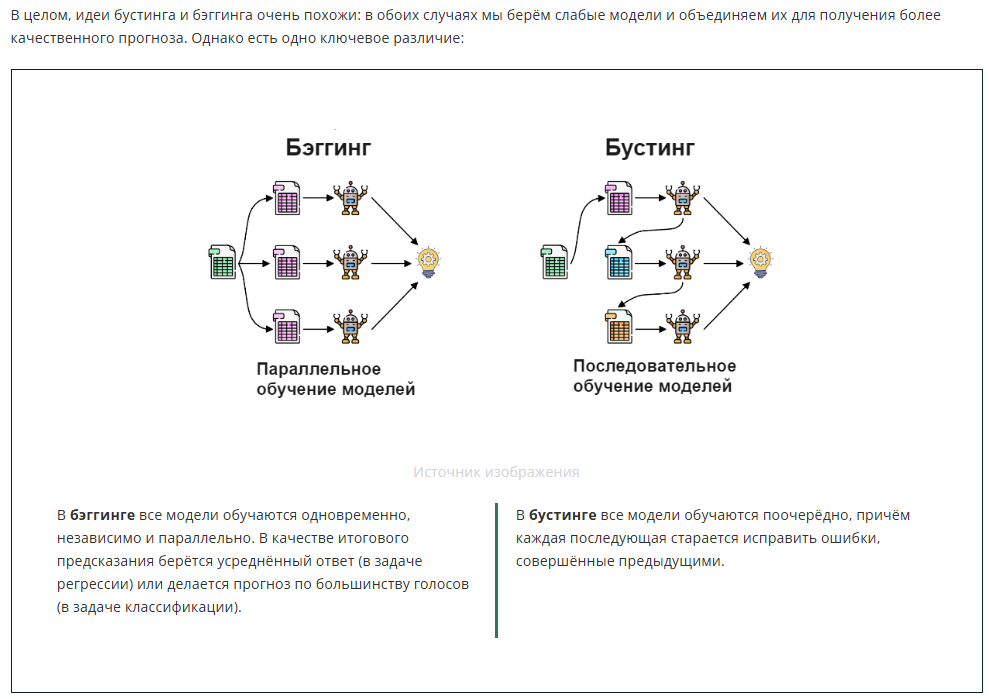

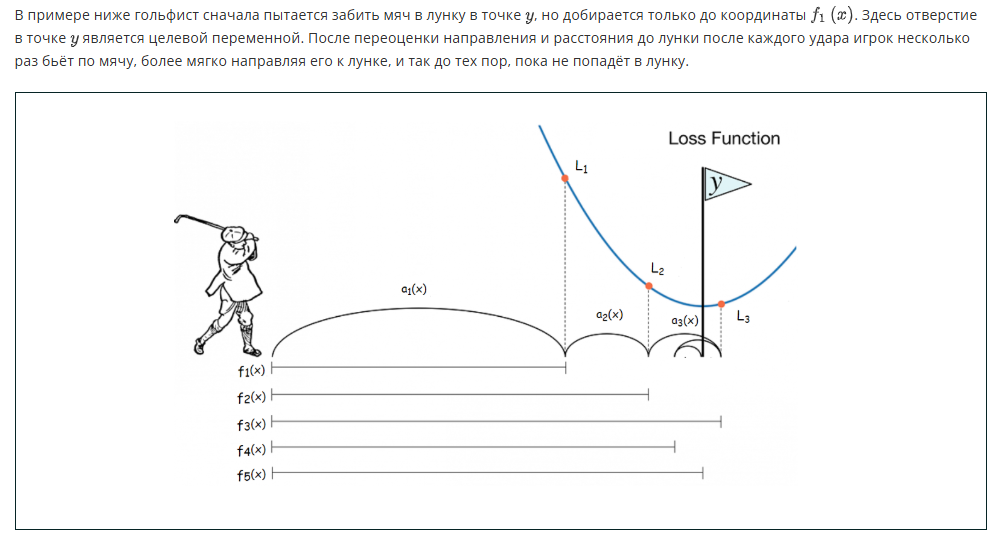

# <center> AdaBoost

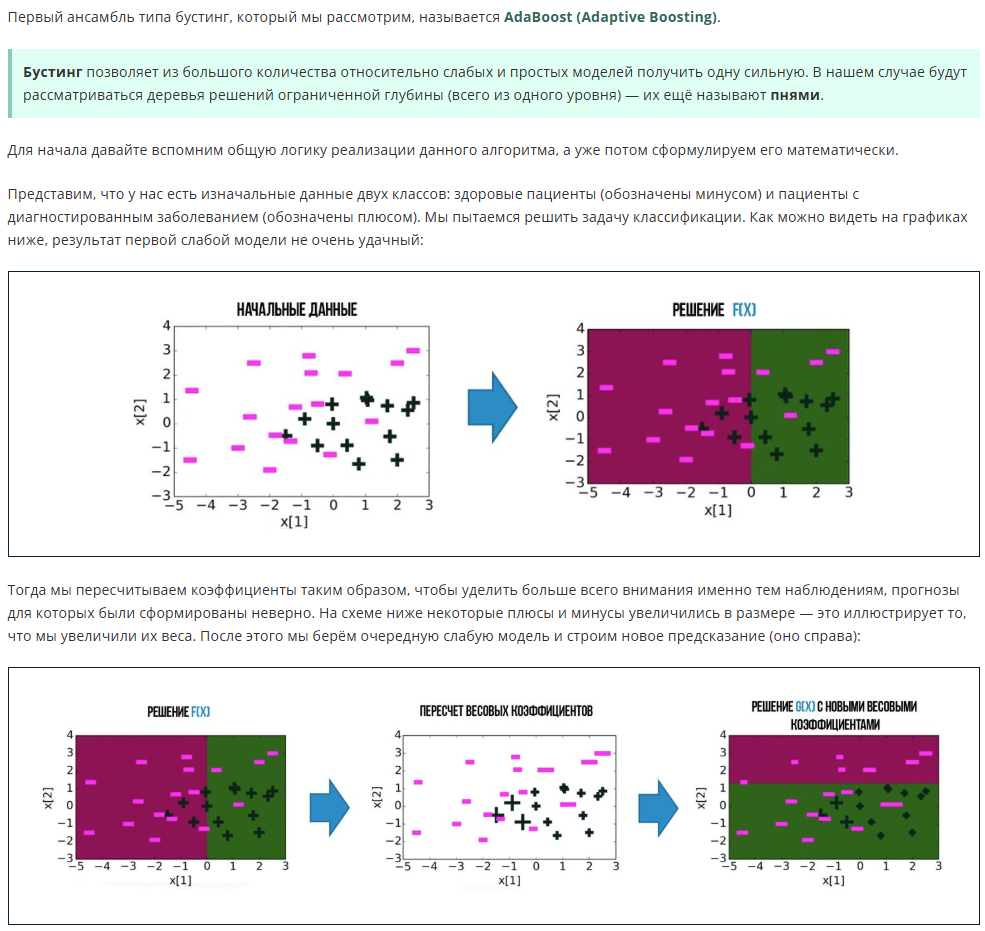

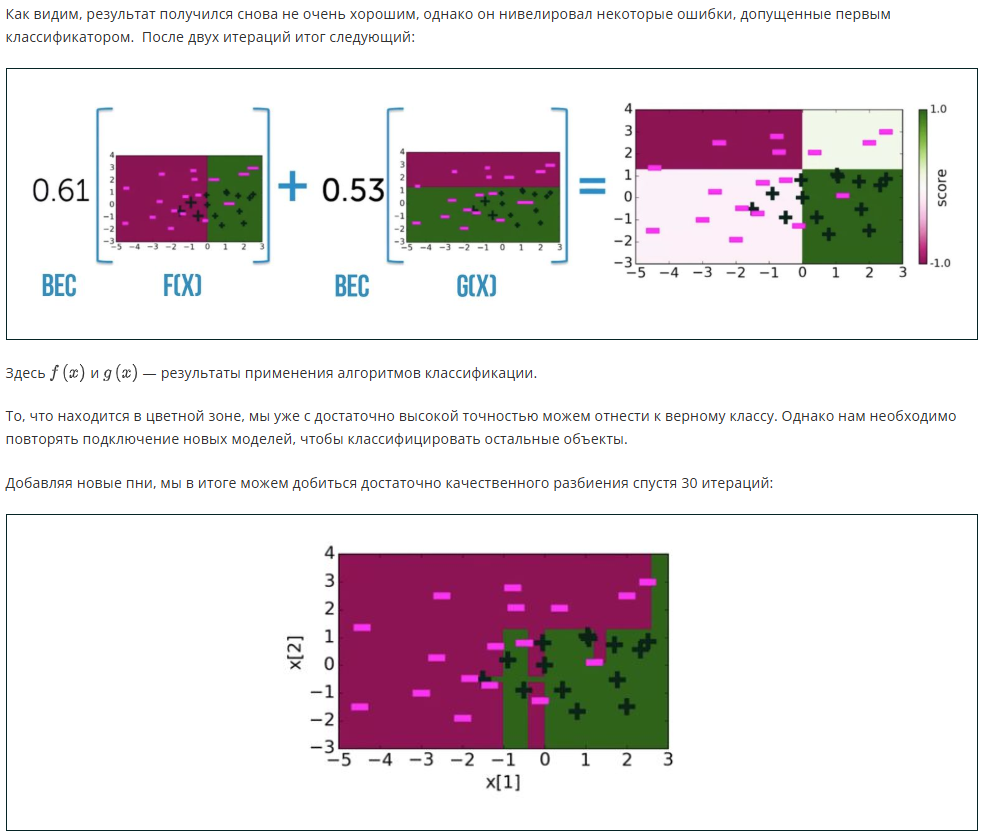

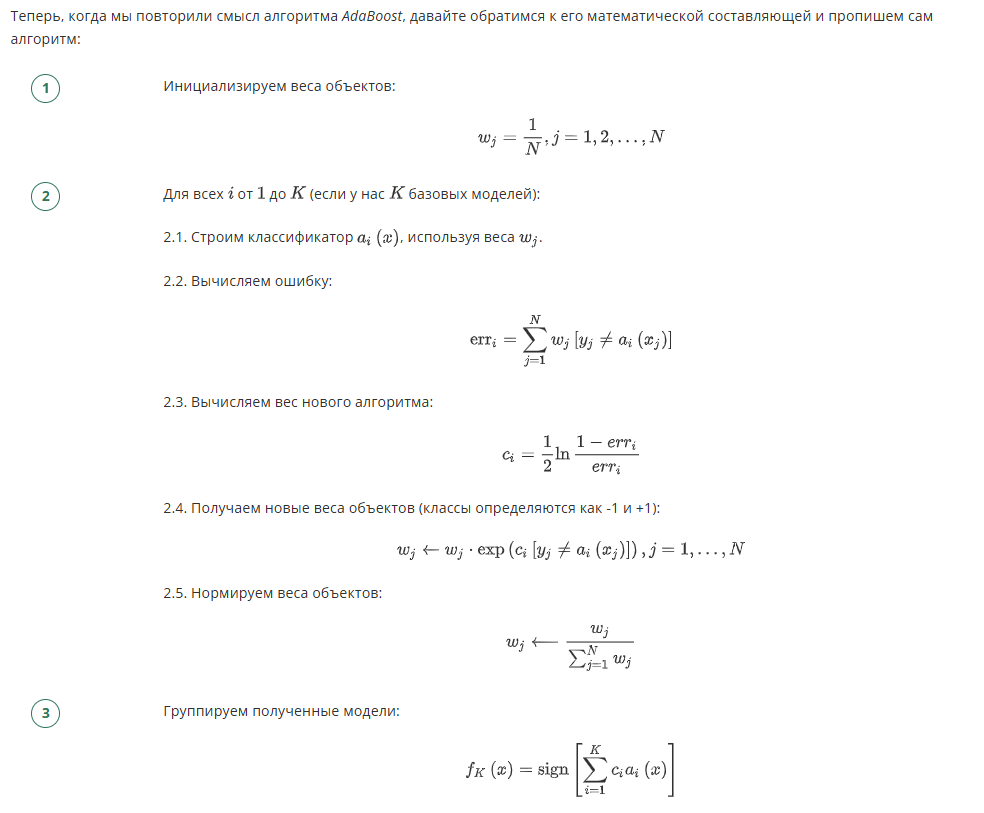

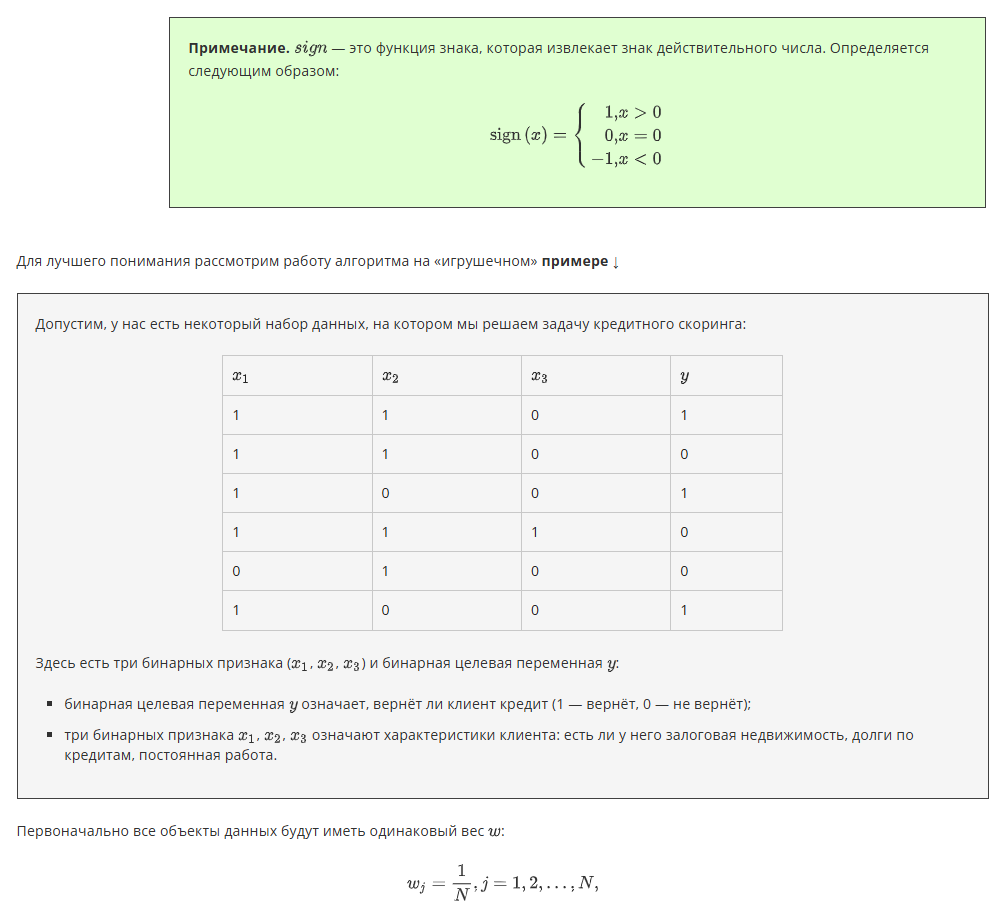

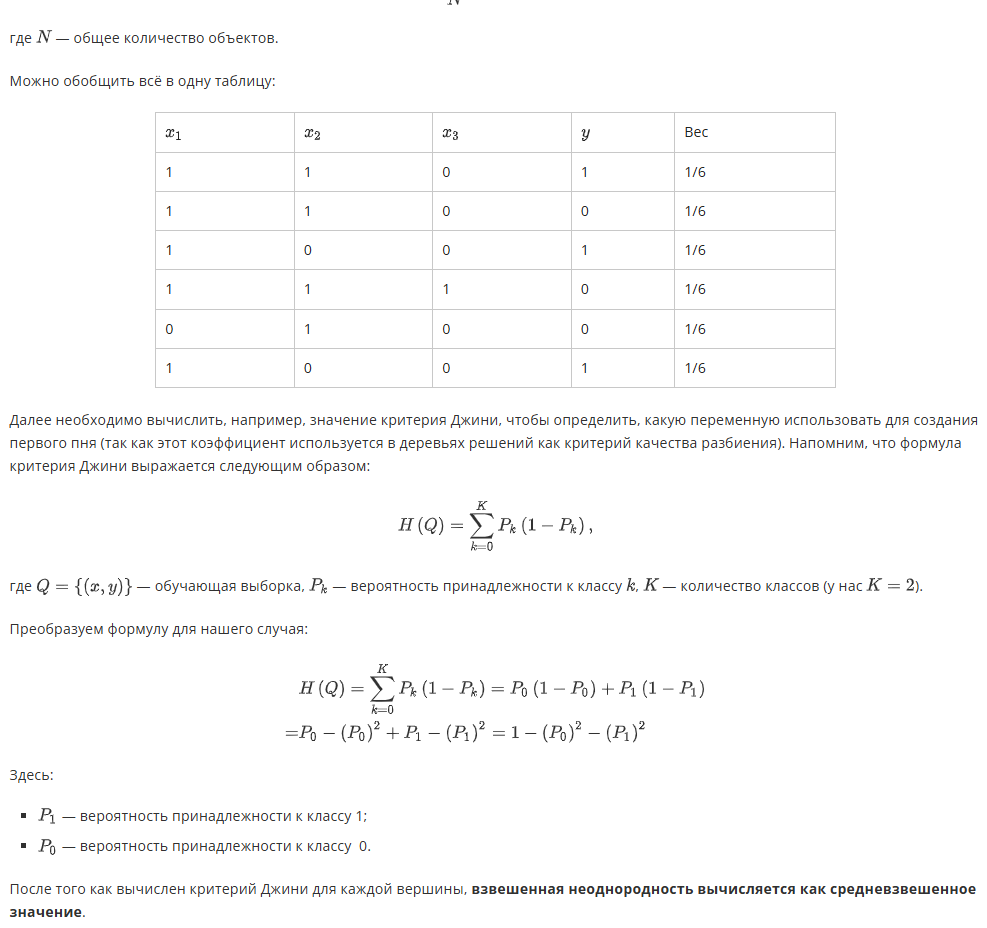

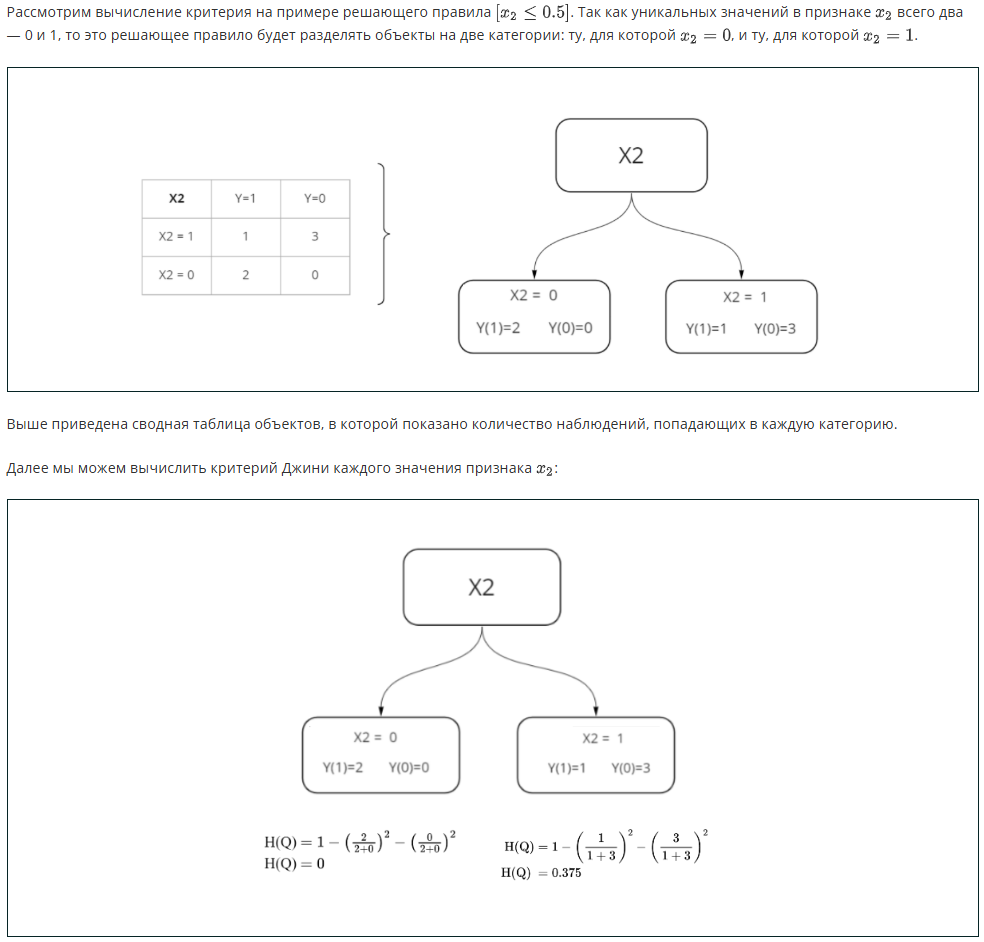

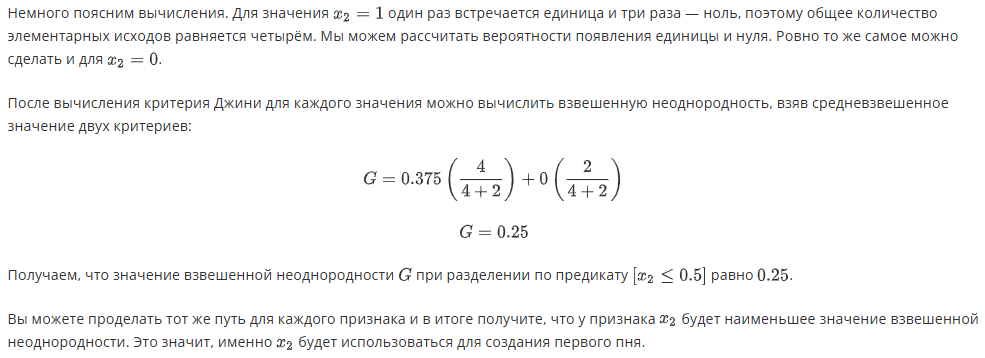

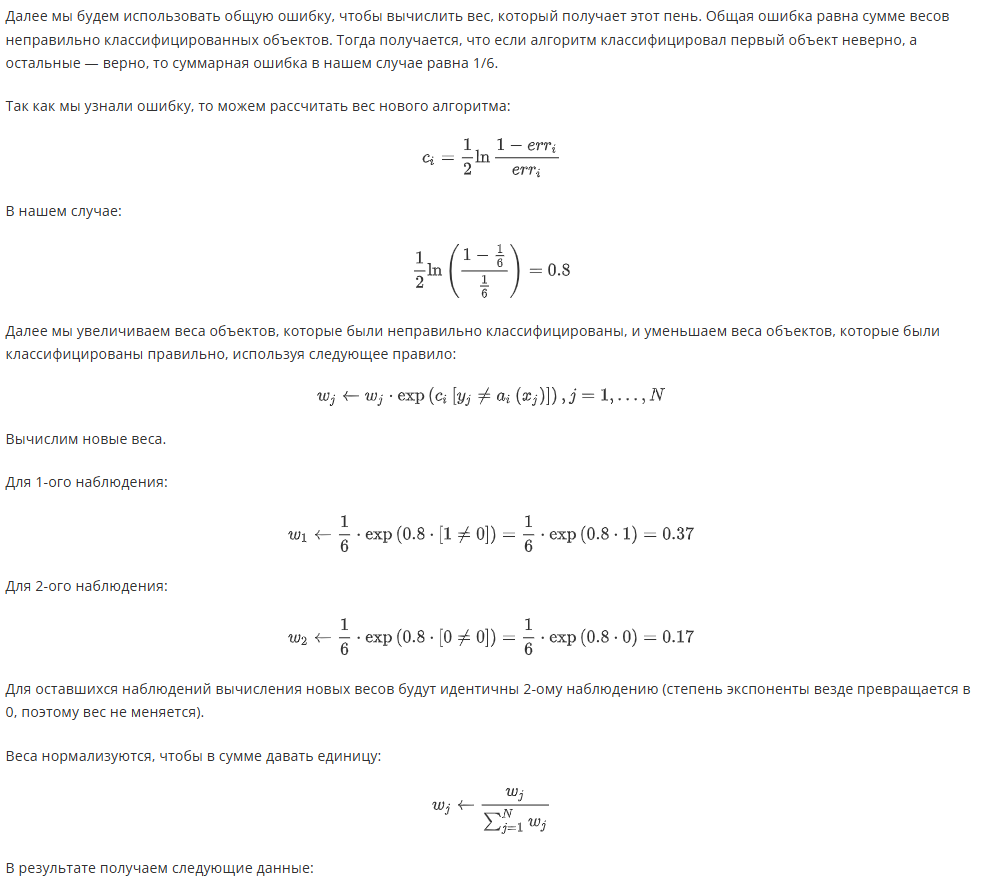

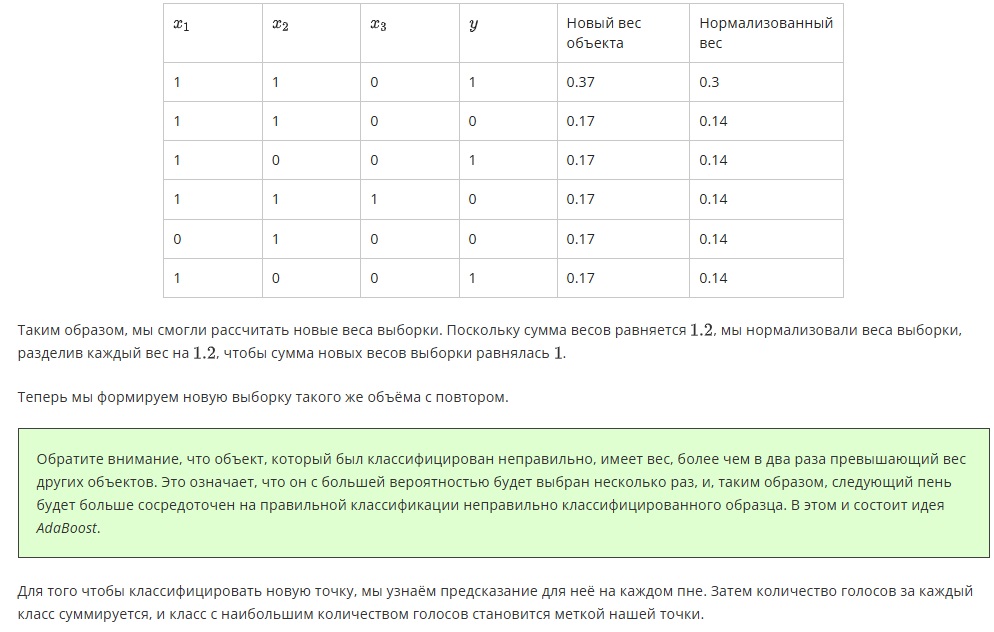

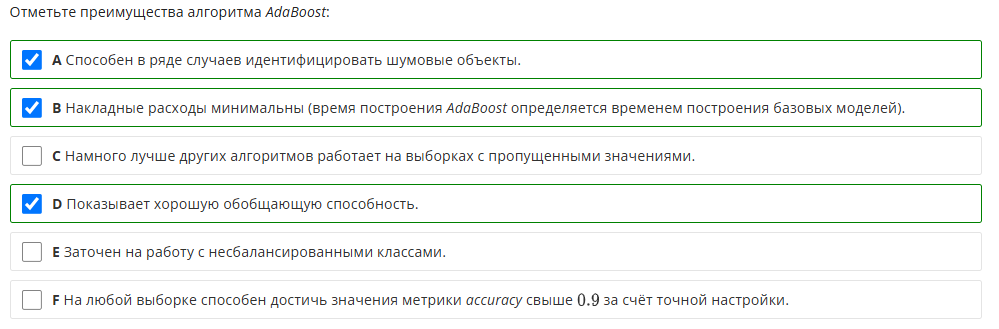

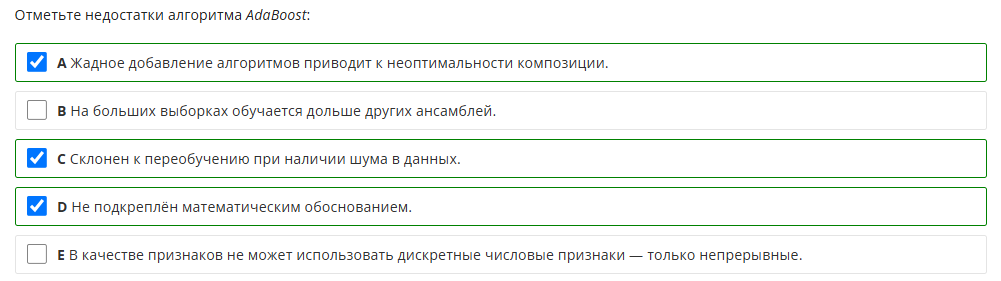

# <center> Градиентный бустинг

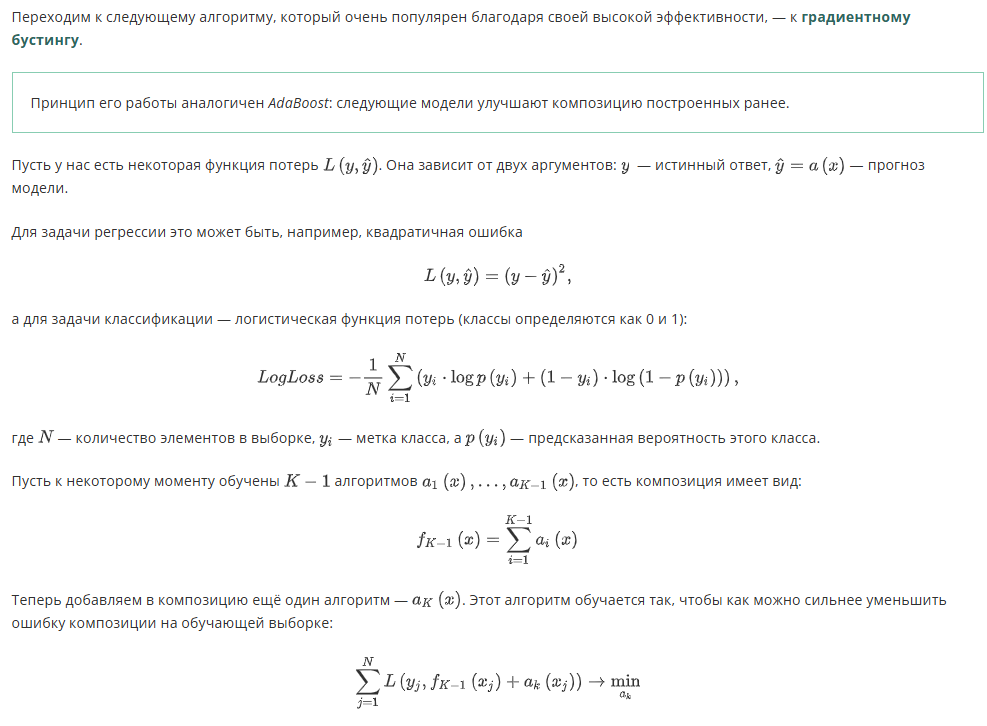

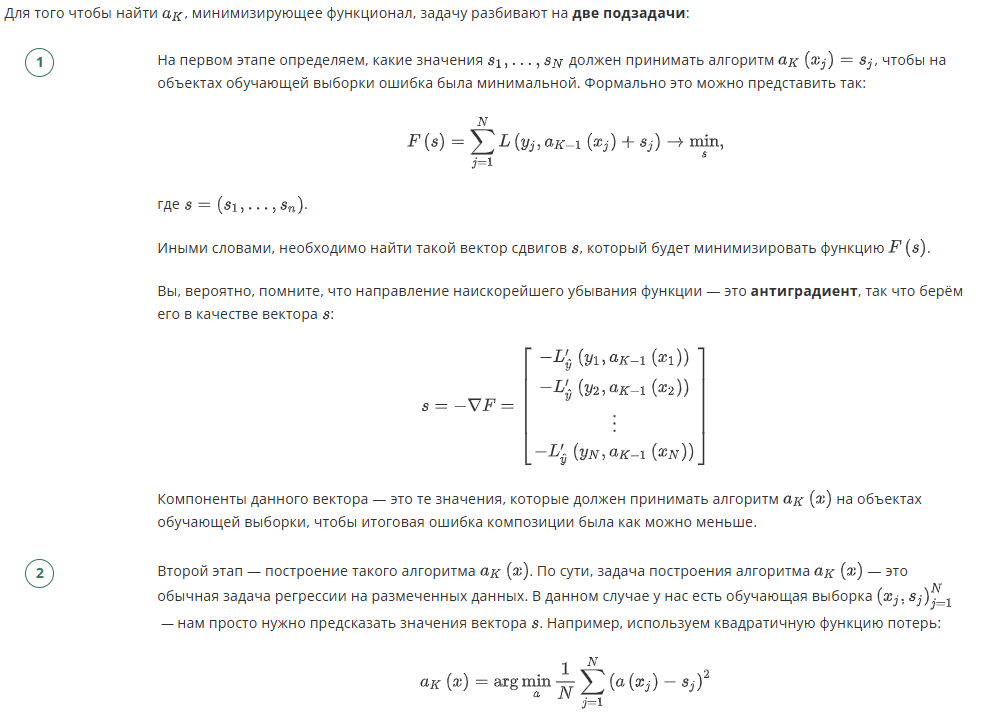

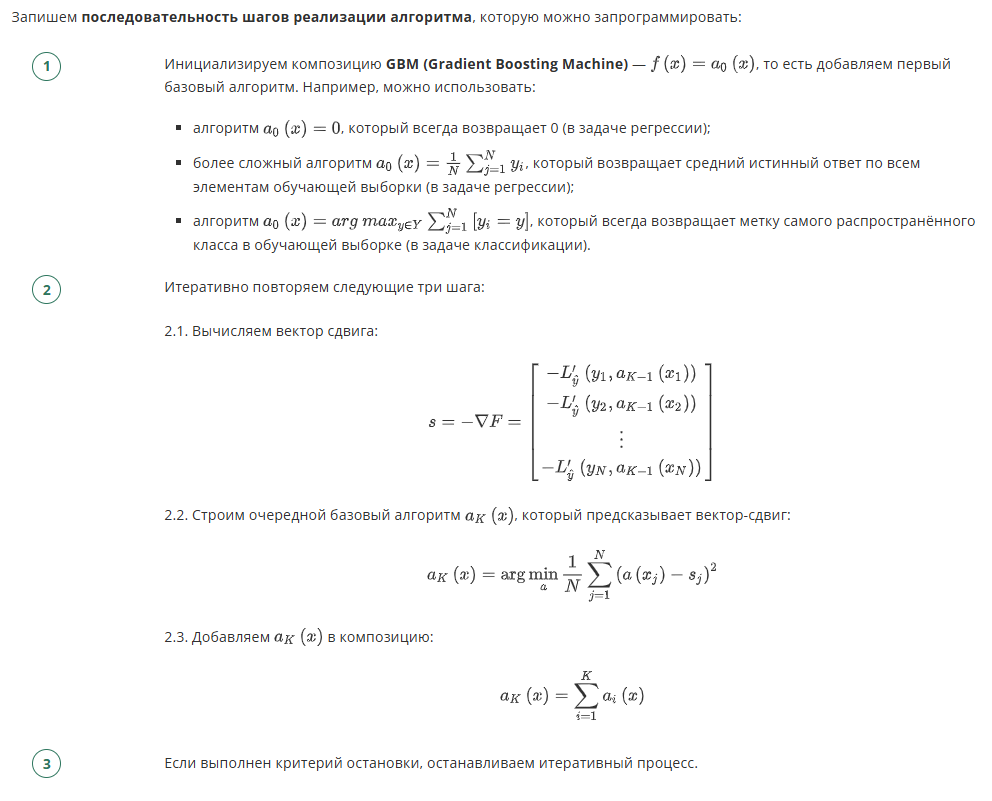

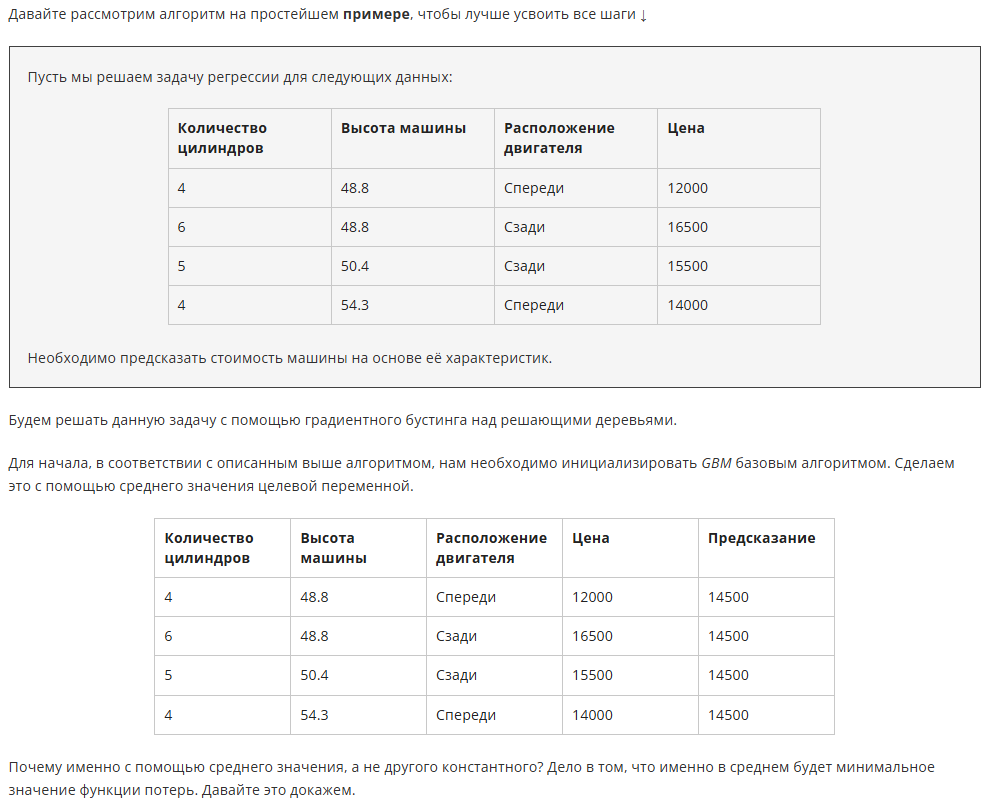

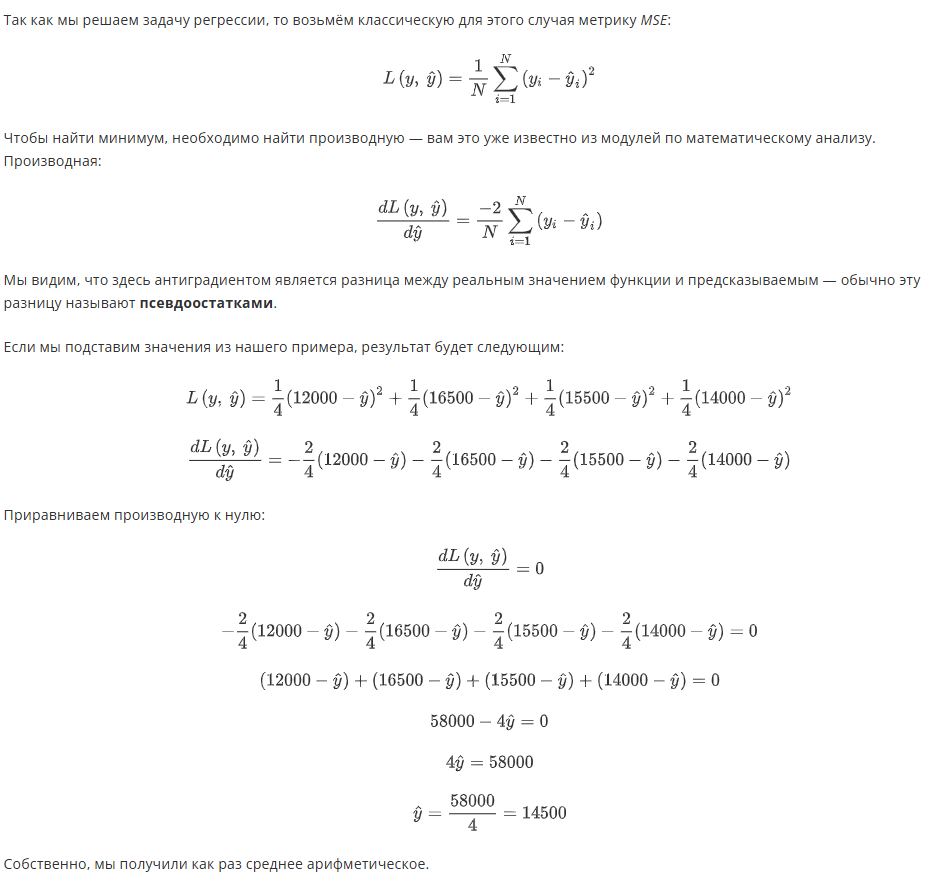

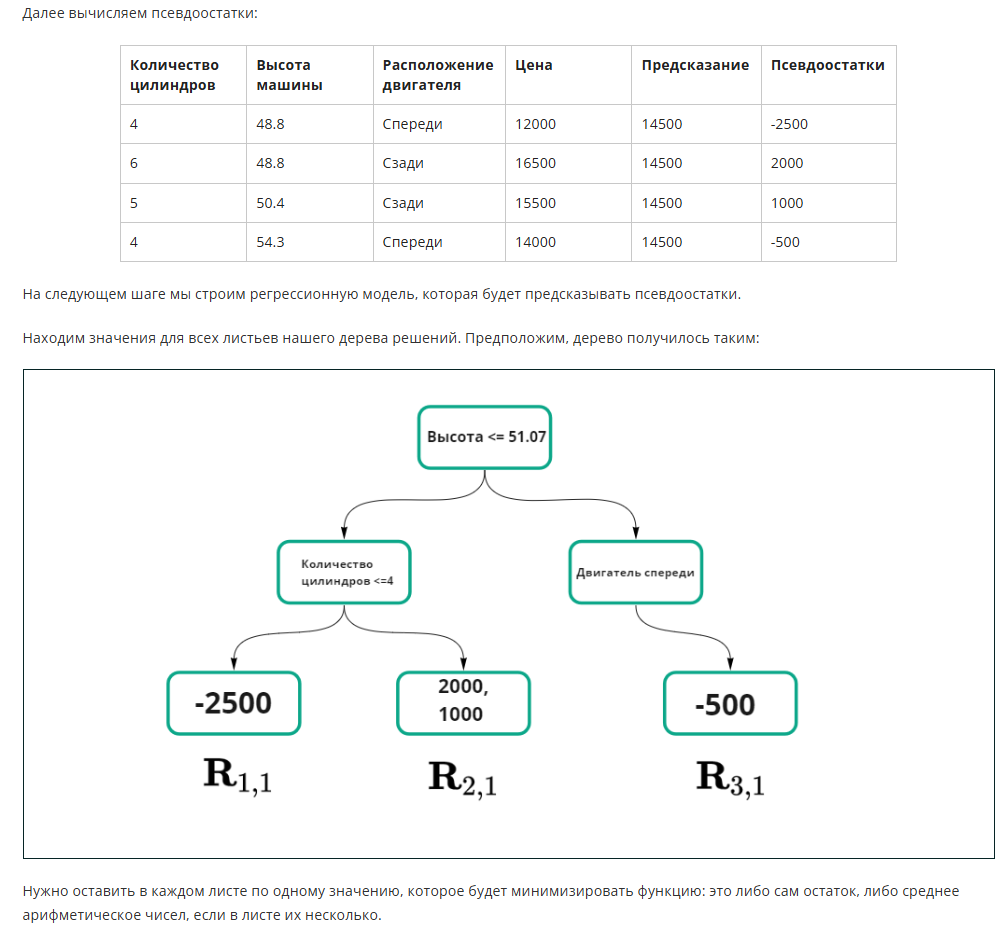

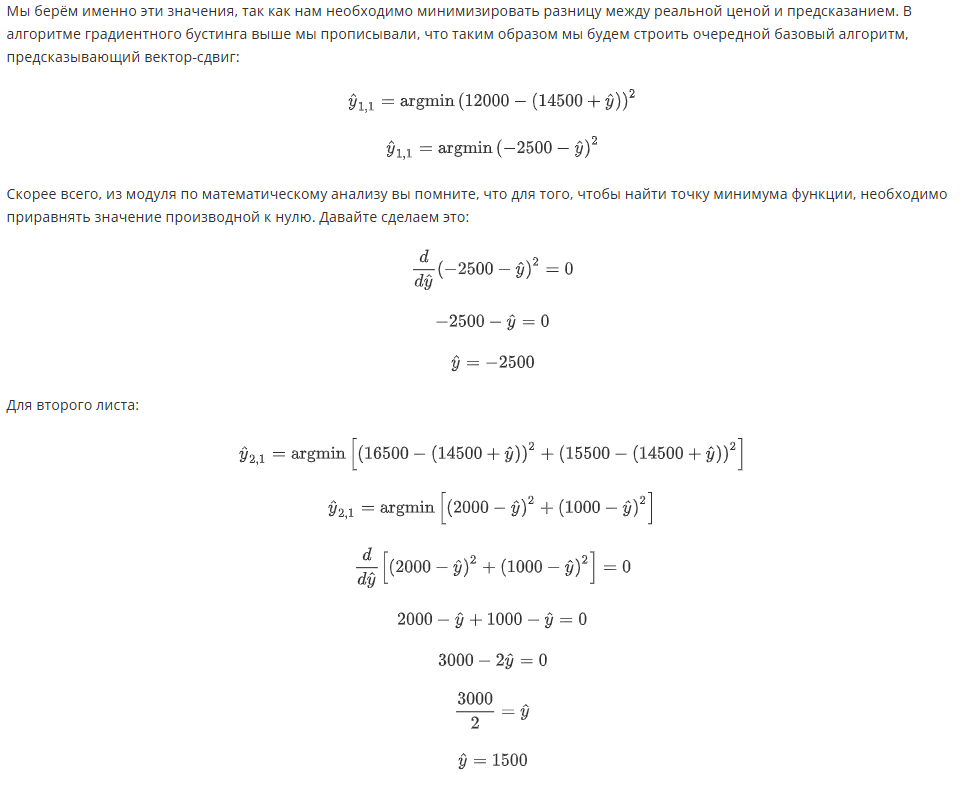

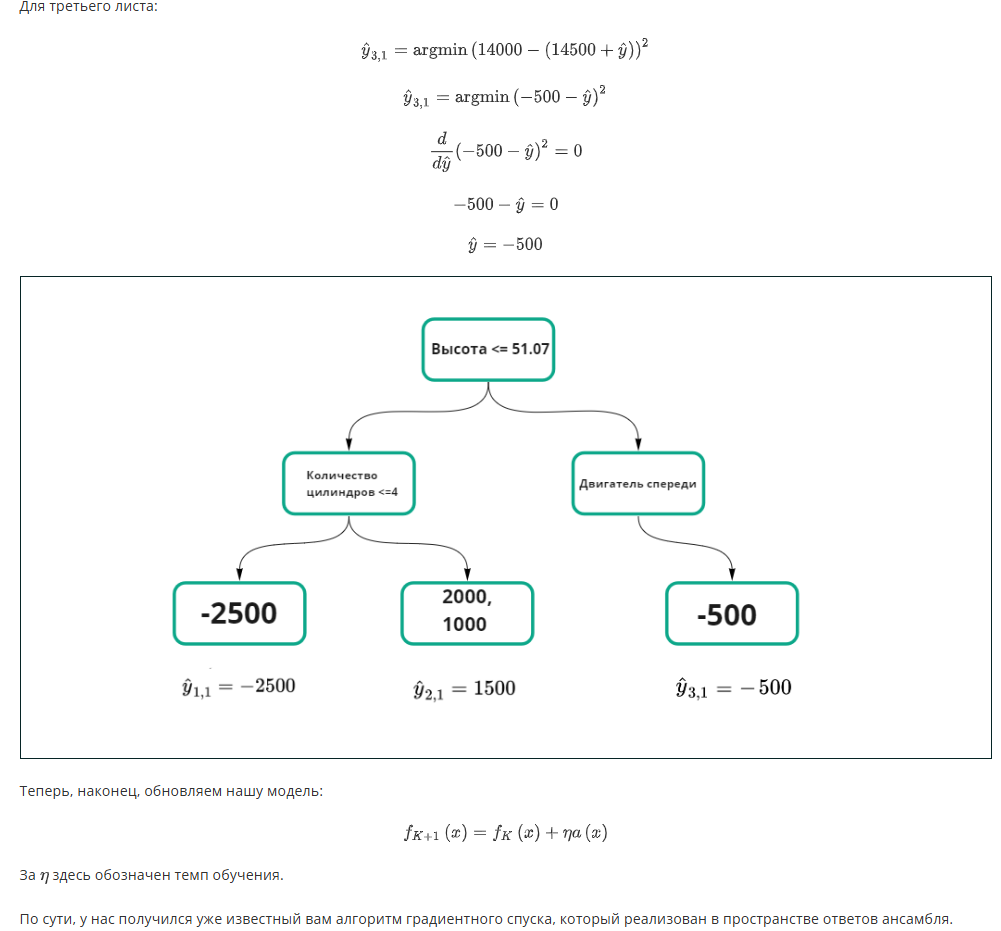

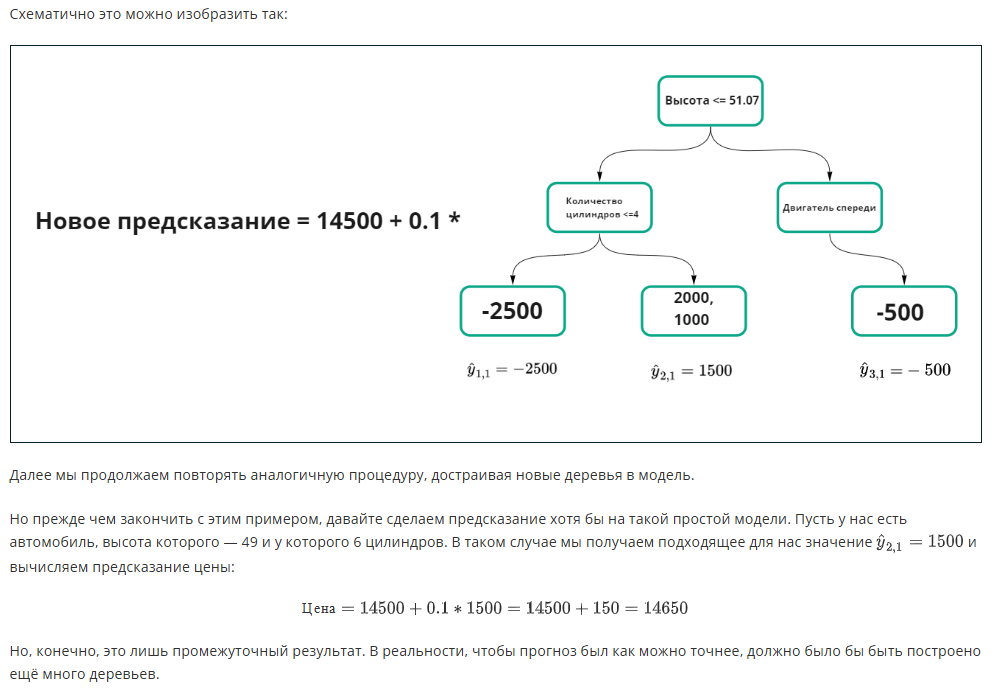

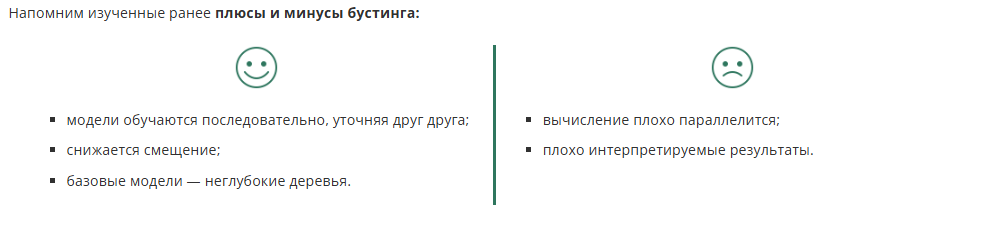

# <center> **XGBoost и CatBoost**

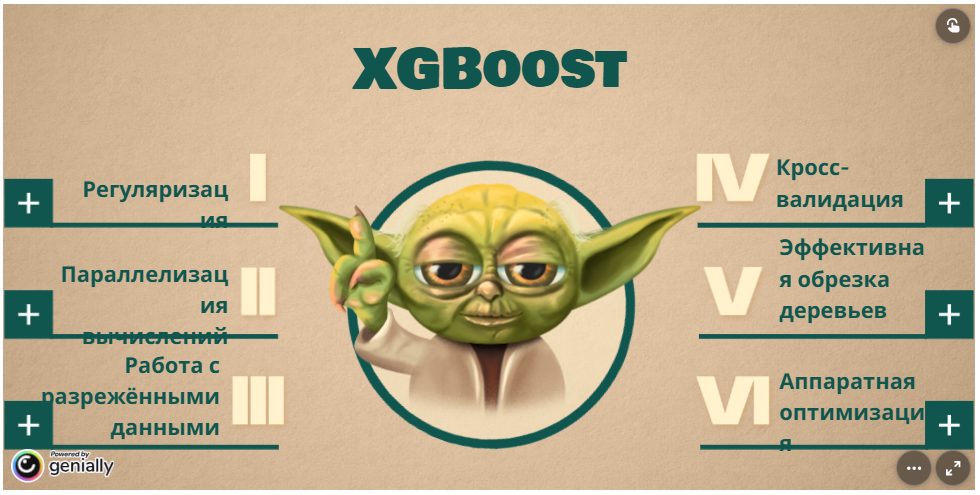

[CatBoost](https://catboost.ai/docs/en/) — это библиотека градиентного бустинга, созданная Яндексом. Её особенность заключается в том, что в ней используются так называемые **небрежные (oblivious) деревья решений**, чтобы «вырастить» сбалансированное дерево.

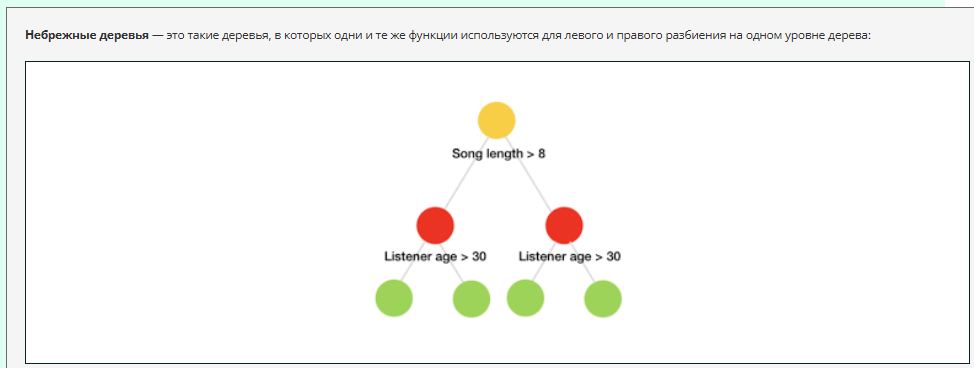

>Одно из главных преимуществ CatBoost заключается в том, что его можно использовать для данных, где категориальные признаки заранее не были преобразованы.

Подробнее узнать о CatBoost можно в [видеопрезентации Яндекса](https://youtu.be/UYDwhuyWYSo).

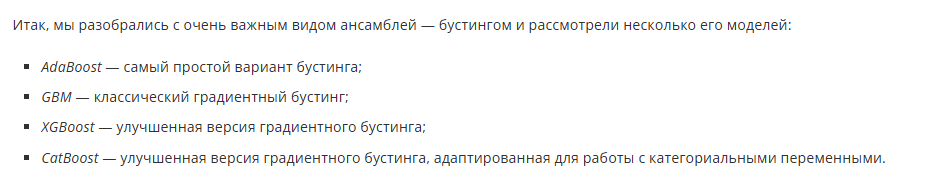

---

# <center> 6. Бустинг. Практика

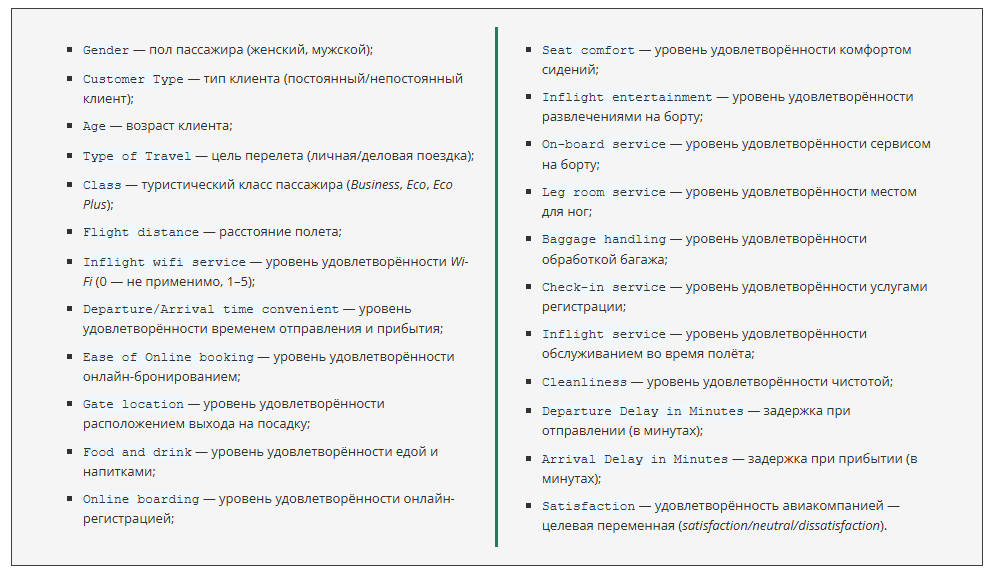

In [75]:
df = pd.read_csv('data/AirPass.csv')
df = df.drop('Unnamed: 0',axis=1)
df.head()

,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [76]:
import xgboost as xgb
import catboost as cb
from sklearn.metrics import f1_score

In [77]:
df.isna().sum().sum()

310

In [81]:
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
print(round(df['Arrival Delay in Minutes'].mean(),2))

15.13
